HC 246脑区平均 INT 与 MDD 246脑区平均 INT 差异

=== 协方差分析 (ANCOVA) 结果 ===
            sum_sq     df         F    PR(>F)
C(Group)  0.011425    1.0  0.176898  0.674671
C(sex)    0.578162    1.0  8.951950  0.003255
age       0.000014    1.0  0.000211  0.988435
mean_fd   0.511633    1.0  7.921854  0.005558
Residual  9.429408  146.0       NaN       NaN

控制年龄、性别和头动(mean_fd)后，组间差异的真实 P 值: 6.746710e-01


/var/folders/dh/dmftg40j21j249nqf2z5v2nh0000gn/T/ipykernel_35570/2635024769.py:51: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.boxplot(
/var/folders/dh/dmftg40j21j249nqf2z5v2nh0000gn/T/ipykernel_35570/2635024769.py:66: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.stripplot(


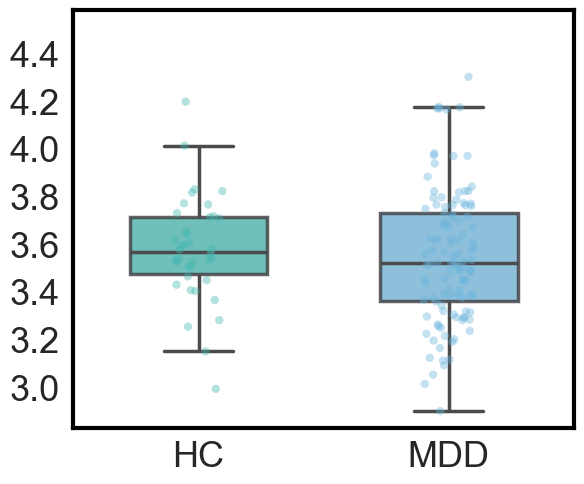

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.api as sm
from statsmodels.formula.api import ols

# ==========================================
# 1. 读取数据与合并
# ==========================================
df_s1 = pd.read_csv(
    '/Volumes/QC/INT/INT_BN246_HC135BP_MDD135BP_DZIII/INT_verify/Step1_HCMDD_Ttest/HC_DZ_INT_agesex_FD.csv'
)
df_s2 = pd.read_csv(
    '/Volumes/QC/INT/INT_BN246_HC135BP_MDD135BP_DZIII/INT_verify/Step1_HCMDD_Ttest/MDD_DZ_INT_agesex_FD.csv'
)

df_s1['Group'] = 'HC'
df_s2['Group'] = 'MDD'

df = pd.concat([df_s1, df_s2], ignore_index=True)
df = df[['Group', 'age', 'sex', 'mean_INT', 'mean_fd']].dropna()

# ==========================================
# 2. 广义线性模型 (GLM) / 协方差分析 (ANCOVA)
# ==========================================
formula = 'mean_INT ~ C(Group) + age + C(sex) + mean_fd'
model = ols(formula, data=df).fit()

anova_table = sm.stats.anova_lm(model, typ=2)
print('=== 协方差分析 (ANCOVA) 结果 ===')
print(anova_table)

target_param = 'C(Group)[T.MDD]'
p_val = model.pvalues.get(target_param, np.nan)
t_val = model.tvalues.get(target_param, np.nan)
print(f'\n控制年龄、性别和头动(mean_fd)后，组间差异的真实 P 值: {p_val:.6e}')

# ==========================================
# 3. 绘制并动态智能标注显著性的箱体图
# ==========================================
plt.figure(figsize=(6, 5))

# 设置画板背景为白色
sns.set_theme(style='white', rc={'axes.facecolor': 'white', 'figure.facecolor': 'white'})

# 自定义颜色字典：HC 为 #42B8B1，MDD 为 #6AB4DC
palette_colors = {'HC': '#42B8B1', 'MDD': '#6AB4DC'}

# 绘制箱体图（通过 linewidth 调粗箱体线条）
ax = sns.boxplot(
    x='Group',
    y='mean_INT',
    data=df,
    order=['HC', 'MDD'],
    palette=palette_colors,
    width=0.55,
    showfliers=False,
    saturation=.85,
    linewidth=2.5,  # 调粗箱体线条
    boxprops={'alpha': 0.8,'edgecolor': '#3C3B3D'},
    # 是否保留箱体的线条
)

# 绘制散点图（通过 size 调大散点圆的大小）
sns.stripplot(
    x='Group',
    y='mean_INT',
    data=df,
    order=['HC', 'MDD'],
    #color='black',
    palette=palette_colors,
    alpha=0.4,
    size=6,  # 调大散点圆的大小
    jitter=True,
)

# 设置四周边框（上下左右轴）为黑色，线条加粗
for spine in ax.spines.values():
  spine.set_edgecolor('black')
  spine.set_linewidth(3)
  spine.set_visible(True)

# 计算画线位置
y_max = df['mean_INT'].max()
y_range = df['mean_INT'].max() - df['mean_INT'].min()
h = y_range * 0.05
line_y = y_max + h

# 如果 p_val < 0.05，则绘制连线和星号
if p_val < 0.05:
  x1, x2 = 0, 1
  plt.plot(
      [x1, x1, x2, x2],
      [line_y, line_y + h, line_y + h, line_y],
      lw=2.5,
      c='black',
  )

  if p_val < 0.001:
    stars = '***'
  elif p_val < 0.01:
    stars = '**'
  else:
    stars = '*'

  plt.text(
      (x1 + x2) * 0.5,
      line_y + h,
      stars,
      ha='center',
      va='bottom',
      color='black',
      fontsize=18,
      fontweight='bold',
  )
plt.xticks(fontsize=26)
plt.yticks(fontsize=26)
# 留出顶部空间
plt.ylim(df['mean_INT'].min() - y_range * 0.05, line_y + h * 3)

# 图表标签
plt.ylabel('', fontsize=12)
plt.xlabel('', fontsize=12)
plt.tight_layout()

# 保存图片
out_fig = '/Volumes/QC/INT/INT_BN246_HC135BP_MDD135BP_DZIII/INT_verify/Step1_HCMDD_Ttest/Fig_HC_MDD_meanINT.png'
plt.savefig(out_fig, dpi=300, bbox_inches='tight')



HC 8网络INT 与 MDD 8网络INT 差异
第一种风格

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf

'''
    HC MDD 8个网络进行比较 INT
    - 统计：使用多元回归 (ANCOVA) 严格控制年龄、性别和头动(mean_fd)，计算显著性
    - 绘图：计算残差以展示去混淆后的数据分布
'''
# ================== 1. 读取数据 ==================
# 确保你的 CSV 文件中包含 'mean_fd' 这一列
hc_df = pd.read_csv(
    '/Volumes/QC/INT/INT_BN246_HC135BP_MDD135BP_DZIII/INT_covariate/Step1_Ttest/HC_INT20_7net_agesex_FD.csv'
)
mdd_df = pd.read_csv(
    '/Volumes/QC/INT/INT_BN246_HC135BP_MDD135BP_DZIII/INT_covariate/Step1_Ttest/MDD_INT20_7net_agesex.csv'
)

# 打标签并合并
hc_df['Group'] = 'HC'
mdd_df['Group'] = 'MDD'
combined_df = pd.concat([hc_df, mdd_df], axis=0).reset_index(drop=True)

# 定义内部原始变量名
networks = [
    'subcortical',
    'Visual',
    'Somatomotor',
    'Dorsal_Attention',
    'Ventral_Attention',
    'Limbic',
    'Frontoparietal',
    'Default',
]

# 定义用于显示在 X 轴上的好看的标签名称
network_labels = [
    'SC',
    'VIS',
    'SMN',
    'DAN',
    'VAN',
    'LIM',
    'FPN',
    'DMN',
]

covariates = ['age', 'sex', 'mean_fd']

print(f'总样本数: {len(combined_df)} (HC: {len(hc_df)}, MDD: {len(mdd_df)})')

# ================== 2. 严谨的统计检验 (多元回归 ANCOVA) ==================
results = []

for net in networks:
  # 回归公式，将 mean_fd 作为连续变量加入模型
  formula = (
      f"{net} ~ C(Group, Treatment(reference='HC')) + age + C(sex) + mean_fd"
  )

  # 拟合 OLS 模型
  model = smf.ols(formula, data=combined_df).fit()

  # 提取 MDD 组相较于 HC 组的主效应系数
  coef_name = "C(Group, Treatment(reference='HC'))[T.MDD]"
  t_stat = model.tvalues[coef_name]
  p_val = model.pvalues[coef_name]

  # 计算原始均值用于表格展示
  hc_raw_mean = combined_df[combined_df['Group'] == 'HC'][net].mean()
  mdd_raw_mean = combined_df[combined_df['Group'] == 'MDD'][net].mean()

  results.append({
      'Network': net,
      'HC_mean_raw': round(hc_raw_mean, 4),
      'MDD_mean_raw': round(mdd_raw_mean, 4),
      't': round(t_stat, 3),
      'p_raw': p_val,
  })

# 转换为 DataFrame 并进行 FDR 校正
from statsmodels.stats.multitest import fdrcorrection

result_df = pd.DataFrame(results)
_, p_fdr = fdrcorrection(result_df['p_raw'], alpha=0.05)
result_df['p_fdr'] = p_fdr
result_df['significant'] = result_df['p_fdr'] < 0.05

# 排序方便查看
result_df = result_df.sort_values('p_fdr')

print('\n=== 多元回归控制 Age/Sex/Mean_FD 后的组间差异 (ANCOVA) ===')
print(result_df)

# ================== 3. 画图数据准备 (回归年龄、性别、头动求残差) ==================
corrected_data = combined_df.copy()

for net in networks:
  mask = combined_df[[net] + covariates].notnull().all(axis=1)
  temp_df = combined_df[mask]

  # 使用包含 mean_fd 的公式来提取残差
  resid_formula = f'{net} ~ age + C(sex) + mean_fd'
  resid_model = smf.ols(resid_formula, data=temp_df).fit()

  # 将残差存回原数据框，加上原始均值保持量级
  corrected_data.loc[mask, net] = resid_model.resid + temp_df[net].mean()

# ================== 4. 绘图 (使用残差数据 + 多元回归的显著性P值) ==================
plt.figure(figsize=(16, 10))

# 设置画板背景为白色
sns.set_theme(style='white', rc={'axes.facecolor': 'white', 'figure.facecolor': 'white'})

# 自定义颜色方案
group_palette = {'HC': '#42B8B1', 'MDD': '#6AB4DC'}

# 转换数据格式以适配 seaborn
plot_data = corrected_data.melt(
    id_vars='Group',
    value_vars=networks,
    var_name='Network',
    value_name='INT',
)

# 绘制箱体图
ax = sns.boxplot(
    x='Network',
    y='INT',
    hue='Group',
    data=plot_data,
    order=networks,  # 确保顺序与原代码一致
    palette=group_palette,
    width=0.6,
    showfliers=False,
    linewidth=1.7,
    boxprops={'alpha': 0.8, 'edgecolor': '#3C3B3D'},
)

# 绘制散点图
sns.stripplot(
    x='Network',
    y='INT',
    hue='Group',
    data=plot_data,
    order=networks,  # 确保顺序与原代码一致
    dodge=True,
    alpha=0.4,
    jitter=True,
    size=5,
    palette=group_palette,
    legend=False,
)

# 设置四周边框（上下左右轴）为黑色，线条加粗
for spine in ax.spines.values():
  spine.set_edgecolor('black')
  spine.set_linewidth(1.7)
  spine.set_visible(True)

# 标注显著性 (根据第二步严谨算出的 result_df)
for i, net in enumerate(networks):
  p = result_df.loc[result_df['Network'] == net, 'p_fdr'].values[0]
  sig = (
      '***'
      if p < 0.001
      else '**' if p < 0.01 else '*' if p < 0.06 else 'n.s.'
  )

  # 找到最大值用于确定文字高度
  y_max = corrected_data[net].max()
  plt.text(i, y_max * 1.02, sig, ha='center', fontsize=18, fontweight='bold')

# 修复重复图例的问题
handles, labels = ax.get_legend_handles_labels()
plt.legend(
    handles[0:2],
    labels[0:2],
    title='',
    loc='upper right',
    fontsize=18,  # 调大图例文字大小
    markerscale=2,  # 调大图例中圆点/符号的相对大小
    frameon=False,
)

plt.ylabel('', fontsize=14)
plt.xlabel('', fontsize=14)

# 修改 X 轴刻度标签为用户指定的新名称
plt.xticks(
    ticks=range(len(networks)), labels=network_labels, fontsize=26
)
plt.yticks(fontsize=26)

# 为了防止星星被图表顶部边缘裁掉，稍微拉高 Y 轴上限
bottom, top = plt.ylim()
plt.ylim(bottom, top + (top - bottom) * 0.05)

plt.tight_layout()
plt.savefig(
    '/Volumes/QC/INT/INT_BN246_HC135BP_MDD135BP_DZIII/INT_covariate/Step1_Ttest/Fig_HCMDD_8NetINT_Diff.png',
    dpi=300,
    bbox_inches='tight',
)
plt.show()

HC 8网络INT 与 MDD 8网络INT 差异
第二种风格

总样本数: 151 (HC: 38, MDD: 113)

=== 多元回归控制 Age/Sex/Mean_FD 后的组间差异 (ANCOVA) ===
             Network  HC_mean_raw  MDD_mean_raw      t     p_raw     p_fdr  \
0        subcortical       3.1470        3.1322 -0.171  0.864193  0.864193   
1             Visual       3.6803        3.7026  0.440  0.660448  0.864193   
2        Somatomotor       3.6894        3.6343 -0.696  0.487256  0.864193   
3   Dorsal_Attention       3.7273        3.7010 -0.203  0.839530  0.864193   
4  Ventral_Attention       3.5929        3.5447 -0.708  0.480136  0.864193   
5             Limbic       3.3169        3.3018 -0.263  0.793253  0.864193   
6     Frontoparietal       3.7987        3.7544 -0.555  0.579413  0.864193   
7            Default       3.7493        3.6865 -0.799  0.425392  0.864193   

   significant  
0        False  
1        False  
2        False  
3        False  
4        False  
5        False  
6        False  
7        False  


/var/folders/dh/dmftg40j21j249nqf2z5v2nh0000gn/T/ipykernel_35570/2279972937.py:127: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/var/folders/dh/dmftg40j21j249nqf2z5v2nh0000gn/T/ipykernel_35570/2279972937.py:135: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.stripplot(
/var/folders/dh/dmftg40j21j249nqf2z5v2nh0000gn/T/ipykernel_35570/2279972937.py:127: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/var/folders/dh/dmftg40j21j249nqf2z5v2nh0000gn/T/ipykernel_35570/2279972937.py:135: FutureWarning: 

Passing `palette` without assigning `hue` is deprec

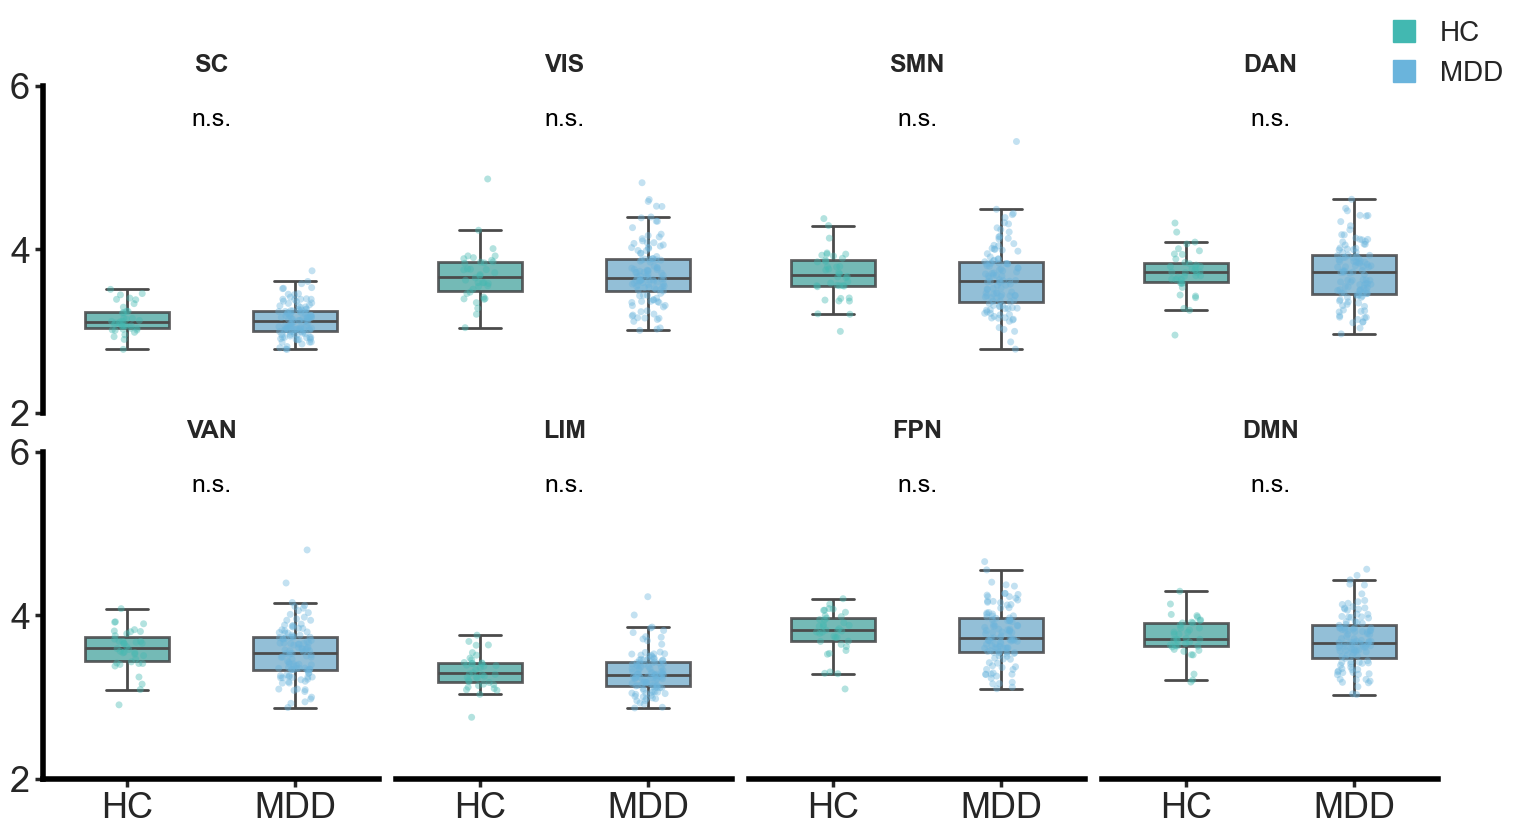


=== 绘图完成！图片已保存至: /Volumes/QC/INT/INT_BN246_HC135BP_MDD135BP_DZIII/INT_verify/Step1_HCMDD_Ttest/Fig_HCMDD_8NetINT_Diff_2x4.png ===


In [4]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.multitest import fdrcorrection

'''
    HC MDD 8个网络进行比较 INT
    - 统计：使用多元回归 (ANCOVA) 严格控制年龄、性别和头动(mean_fd)，计算显著性
    - 绘图：2x4 子图布局。仅第一列保留 Y 轴；仅第二行保留 X 轴；所有子图均不要上轴和右轴。
'''
# ================== 1. 读取数据 ==================
hc_df = pd.read_csv(
    '/Volumes/QC/INT/INT_BN246_HC135BP_MDD135BP_DZIII/INT_verify/HC_DZ_INT_8net.csv'
)
mdd_df = pd.read_csv(
    '/Volumes/QC/INT/INT_BN246_HC135BP_MDD135BP_DZIII/INT_verify/MDD_DZ_INT_8net.csv'
)

# 打标签并合并
hc_df['Group'] = 'HC'
mdd_df['Group'] = 'MDD'
combined_df = pd.concat([hc_df, mdd_df], axis=0).reset_index(drop=True)

# 定义内部原始变量名
networks = [
    'subcortical',
    'Visual',
    'Somatomotor',
    'Dorsal_Attention',
    'Ventral_Attention',
    'Limbic',
    'Frontoparietal',
    'Default',
]

# 定义用于显示在子图标题上的名称
network_labels = [
    'SC',
    'VIS',
    'SMN',
    'DAN',
    'VAN',
    'LIM',
    'FPN',
    'DMN',
]

covariates = ['age', 'sex', 'mean_fd']

print(f'总样本数: {len(combined_df)} (HC: {len(hc_df)}, MDD: {len(mdd_df)})')

# ================== 2. 严谨的统计检验 (多元回归 ANCOVA) ==================
results = []

for net in networks:
  formula = f"{net} ~ C(Group, Treatment(reference='HC')) + age + C(sex) + mean_fd"
  model = smf.ols(formula, data=combined_df).fit()

  coef_name = "C(Group, Treatment(reference='HC'))[T.MDD]"
  t_stat = model.tvalues[coef_name]
  p_val = model.pvalues[coef_name]

  hc_raw_mean = combined_df[combined_df['Group'] == 'HC'][net].mean()
  mdd_raw_mean = combined_df[combined_df['Group'] == 'MDD'][net].mean()

  results.append({
      'Network': net,
      'HC_mean_raw': round(hc_raw_mean, 4),
      'MDD_mean_raw': round(mdd_raw_mean, 4),
      't': round(t_stat, 3),
      'p_raw': p_val,
  })

result_df = pd.DataFrame(results)
_, p_fdr = fdrcorrection(result_df['p_raw'], alpha=0.05)
result_df['p_fdr'] = p_fdr
result_df['significant'] = result_df['p_fdr'] < 0.05

print('\n=== 多元回归控制 Age/Sex/Mean_FD 后的组间差异 (ANCOVA) ===')
print(result_df.sort_values('p_fdr'))

# ================== 3. 画图数据准备 (回归年龄、性别、头动求残差) ==================
corrected_data = combined_df.copy()

for net in networks:
  mask = combined_df[[net] + covariates].notnull().all(axis=1)
  temp_df = combined_df[mask]

  resid_formula = f'{net} ~ age + C(sex) + mean_fd'
  resid_model = smf.ols(resid_formula, data=temp_df).fit()
  corrected_data.loc[mask, net] = resid_model.resid + temp_df[net].mean()

# 计算全局 Y 轴的统一范围，保证所有的子图在视觉上量级一致
all_vals = []
for net in networks:
  all_vals.extend(corrected_data[net].dropna().values)
global_y_min = min(all_vals)
global_y_max = max(all_vals)
global_y_range = global_y_max - global_y_min
h_global = global_y_range * 0.05

# 预留顶部空间给显著性星号，计算统一的 ylim
unified_ylim_top = global_y_max + h_global * 4
unified_ylim_bottom = global_y_min - global_y_range * 0.05

# 【修改点】：如果你希望固定 Y 轴刻度为 [2, 4, 6] 或根据数据动态生成合适的整步长，
# 可以通过 np.arange 统一设定，这里设定一个覆盖全局的合理刻度（例如 2 到 6 之间）
custom_yticks = [2, 4, 6]

# ================== 4. 分层绘图 (2行 4列) ==================
sns.set_theme(style='white', rc={'axes.facecolor': 'white', 'figure.facecolor': 'white'})
group_palette = {'HC': '#42B8B1', 'MDD': '#6AB4DC'}

fig, axes = plt.subplots(nrows=2, ncols=4, figsize=(18, 9))
axes = axes.flatten()

for i, (net, label) in enumerate(zip(networks, network_labels)):
  ax = axes[i]

  df_net = corrected_data[['Group', net]].dropna().copy()
  df_net.rename(columns={net: 'INT'}, inplace=True)

  # 绘制箱体图
  sns.boxplot(
      x='Group', y='INT', data=df_net, order=['HC', 'MDD'],
      palette=group_palette, width=0.5, showfliers=False,
      linewidth=2, boxprops={'alpha': 0.8, 'edgecolor': '#3C3B3D'},
      ax=ax
  )

  # 绘制散点图
  sns.stripplot(
      x='Group', y='INT', data=df_net, order=['HC', 'MDD'],
      dodge=False, alpha=0.4, jitter=True, size=5,
      palette=group_palette, legend=False, ax=ax
  )

  ax.set_xlim(-0.5, 1.5)

  # 1. 强制去除上边框和右边框
  ax.spines['top'].set_visible(False)
  ax.spines['right'].set_visible(False)

  # 设置子图标题和重置默认标签
  ax.set_title(label, fontsize=18, fontweight='bold', pad=10)
  ax.set_xlabel('')

  # 统一设置全局共享的 Y 轴范围
  ax.set_ylim(unified_ylim_bottom, unified_ylim_top)

  # 【修改点】：如果需要锁定特定的刻度（如 [2, 4, 6]），可以解开下面这行注释：
  ax.set_yticks(custom_yticks)

  # 2. 定制化 Y 轴：只在第一列保留
  if i % 4 == 0:
      ax.spines['left'].set_color('black')
      ax.spines['left'].set_linewidth(4)  # Y轴主线加粗
      ax.spines['left'].set_visible(True)
      ax.set_ylabel('', fontsize=26, fontweight='bold')
      # 【修改点】：通过 width=2.5, length=6 将 Y 轴刻度小短线加粗加大
      ax.tick_params(axis='y', labelsize=26, left=True, width=2.5, length=6)
  else:
      ax.spines['left'].set_visible(False)
      ax.set_ylabel('')
      ax.tick_params(axis='y', left=False, labelleft=False)

  # 3. 定制化 X 轴：只在第二行保留
  if i >= 4:
      ax.spines['bottom'].set_color('black')
      ax.spines['bottom'].set_linewidth(4)  # X轴主线加粗
      ax.spines['bottom'].set_visible(True)
      ax.set_xticklabels(['HC', 'MDD'], fontsize=26)
      # 【修改点】：通过 width=2.5, length=6 将 X 轴刻度小短线加粗加大
      ax.tick_params(axis='x', bottom=True, labelbottom=True, width=2.5, length=6)
  else:
      ax.spines['bottom'].set_visible(False)
      ax.set_xticklabels([])
      ax.tick_params(axis='x', bottom=False, labelbottom=False)

  # 绘制显著性连线和星号
  p = result_df.loc[result_df['Network'] == net, 'p_fdr'].values[0]
  sig = '***' if p < 0.001 else '**' if p < 0.01 else '*' if p < 0.06 else 'n.s.'

  line_y = global_y_max + h_global

  if sig != 'n.s.':
      ax.plot([0, 0, 1, 1], [line_y, line_y + h_global, line_y + h_global, line_y], lw=2.5, c='black')
      ax.text(0.5, line_y + h_global, sig, ha='center', va='bottom', color='black', fontsize=18, fontweight='bold')
  else:
      ax.text(0.5, line_y, sig, ha='center', va='bottom', color='black', fontsize=18)

# 添加全局的统一图例
import matplotlib.lines as mlines
hc_patch = mlines.Line2D([], [], color='#42B8B1', marker='s', linestyle='None', markersize=16, label='HC')
mdd_patch = mlines.Line2D([], [], color='#6AB4DC', marker='s', linestyle='None', markersize=16, label='MDD')

fig.legend(handles=[hc_patch, mdd_patch], loc='upper right', bbox_to_anchor=(0.95, 0.98),
           fontsize=20, frameon=False, ncol=1, handletextpad=0.3)

# 调整子图间距
plt.subplots_adjust(hspace=0.12, wspace=0.05)

out_fig = '/Volumes/QC/INT/INT_BN246_HC135BP_MDD135BP_DZIII/INT_verify/Step1_HCMDD_Ttest/Fig_HCMDD_8NetINT_Diff_2x4.png'
plt.savefig(out_fig, dpi=300, bbox_inches='tight')
plt.show()

print(f'\n=== 绘图完成！图片已保存至: {out_fig} ===')

HC subtype1 subtype2 BNA246脑区mean INT 差异比较
箱体填充风格

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from statsmodels.conftest import matplotlib
from statsmodels.formula.api import ols
from statsmodels.stats.multitest import multipletests
import seaborn as sns

matplotlib.use('Agg')
# =========================================================
# 1. 读取文件与数据合并
# =========================================================
base_dir = '/Volumes/QC/INT/INT_BN246_HC135BP_MDD135BP_DZIII/INT_covariate/Step2_subtype/Step2_BN246mean_INT/'
# 注意：请确保以下读取的csv文件中都包含 'mean_fd' 列
df_hc = pd.read_csv(base_dir + 'HC_BN246_meanINT_agesex_FD.csv')
df_s1 = pd.read_csv(base_dir + 'subtype1_mean_INT_agesex_FD.csv')
df_s2 = pd.read_csv(base_dir + 'subtype2_mean_INT_agesex_FD.csv')

df_hc['group'] = 'HC'
df_s1['group'] = 'Subtype1'
df_s2['group'] = 'Subtype2'

df = pd.concat([df_hc, df_s1, df_s2], ignore_index=True)

# 【修改点 1】：在提取列时，加入 'mean_fd' 并去除缺失值
df = df[['group', 'age', 'sex', 'mean_INT', 'mean_fd']].dropna()

# =========================================================
# 2. ANCOVA 主效应模型构建
# =========================================================
# 【修改点 2】：将 mean_fd 添加到线性回归模型公式中
model = ols('mean_INT ~ C(group) + age + C(sex) + mean_fd', data=df).fit()

# 计算协方差分析表 (主效应) 并保存
anova_table = sm.stats.anova_lm(model, typ=2)
print('========== 协方差分析表 (ANCOVA 主效应) ==========')
print(anova_table)
anova_table.to_csv(
    base_dir + 'Diff_mean_INT_ANCOVA_MainEffect_covFD.csv'
)  # 更新文件名以示区别

# =========================================================
# 3. 事后检验分析 (Pairwise Comparisons) 与 FDR 校正
# =========================================
pairwise_results = []
# 这里的 contrast 不变，因为我们只关心 C(group) 的差异，其他协变量 (age, sex, mean_fd) 在对比时保持不变（互相抵消）
contrasts = {
    'HC_vs_Subtype1': "C(group)[T.Subtype1] = 0",
    'HC_vs_Subtype2': "C(group)[T.Subtype2] = 0",
    'Subtype1_vs_Subtype2': 'C(group)[T.Subtype1] - C(group)[T.Subtype2] = 0',
}

for comp_name, contrast_str in contrasts.items():
  t_test_res = model.t_test(contrast_str)
  p_val = (
      t_test_res.pvalue.item()
      if hasattr(t_test_res.pvalue, 'item')
      else float(t_test_res.pvalue)
  )
  t_val = (
      t_test_res.tvalue.item()
      if hasattr(t_test_res.tvalue, 'item')
      else float(t_test_res.tvalue)
  )
  pairwise_results.append(
      {'Comparison': comp_name, 't_value': t_val, 'p_uncorrected': p_val}
  )

pairwise_df = pd.DataFrame(pairwise_results)

# 对这 3 次两两比较进行 FDR 多重比较校正
_, p_fdr_pair, _, _ = multipletests(
    pairwise_df['p_uncorrected'], alpha=0.05, method='fdr_bh'
)
pairwise_df['p_FDR'] = p_fdr_pair


def get_stars(p):
  if p < 0.001:
    return '***'
  elif p < 0.01:
    return '**'
  elif p < 0.05:
    return '*'
  else:
    return 'ns'


pairwise_df['Significance'] = pairwise_df['p_FDR'].apply(get_stars)

# 保存事后检验详细结果
pairwise_df.to_csv(
    base_dir + 'Diff_mean_INT_ANCOVA_Pairwise_covFD.csv', index=False
)
print('\n========== 事后两两比较 (FDR 校正) ==========')
print(pairwise_df)


# =========================================================
# 4. 绘制并动态智能标注显著性的箱体图
# ==========================================
plt.figure(figsize=(8, 6))

# 【修改点】设置画板背景为白色，边框加粗
sns.set_theme(style='white', rc={'axes.facecolor': 'white', 'figure.facecolor': 'white'})

# 【修改点】自定义配色字典
custom_palette = {'HC': '#42B8B1', 'Subtype1': '#B50A27', 'Subtype2': '#00478D'}

# 绘制箱体图
ax = sns.boxplot(
    x='group',
    y='mean_INT',
    data=df,
    order=['HC', 'Subtype1', 'Subtype2'],
    palette=custom_palette,
    width=0.5,
    showfliers=False,
    linewidth=1.7,
    boxprops={'alpha': 0.8, 'edgecolor': '#3C3B3D'}, # #3C3B3D
)
# groups_order = ['HC', 'Subtype1', 'Subtype2']
# # 【修复点】：使用 enumerate 提取索引 i，解决原代码中字符串相乘报错的问题
# for i, group_name in enumerate(groups_order):
#     group_color = '#3C3B3D'
#     group_color = custom_palette[group_name]
#     # boxplot 生成的线条包含 whiskers(须), caps(盖帽), medians(中位数线)
#     ax.lines[i*5 + 0].set_color(group_color)  # whisker 1
#     ax.lines[i*5 + 1].set_color(group_color)  # whisker 2
#     ax.lines[i*5 + 2].set_color(group_color)  # cap 1
#     ax.lines[i*5 + 3].set_color(group_color)  # cap 2
#     ax.lines[i*5 + 4].set_color(group_color)  # median linemedian line
# 绘制散点图
sns.stripplot(
    x='group',
    y='mean_INT',
    data=df,
    order=['HC', 'Subtype1', 'Subtype2'],
    palette=custom_palette,
    alpha=0.5,
    size=6,
    jitter=True,
)

# 设置四周边框（上下左右轴）为黑色，线条加粗
for spine in ax.spines.values():
  spine.set_edgecolor('black')
  spine.set_linewidth(1.7)
  spine.set_visible(True)

y_max = df['mean_INT'].max()
y_min = df['mean_INT'].min()
y_range = y_max - y_min

# 连线的动态高度步长和拐角小尾巴长度
step = 0.08 * y_range
h = 0.02 * y_range
current_y = y_max + 0.05 * y_range

# 提取 FDR 校正后的星号
star_hc_s1 = pairwise_df[pairwise_df['Comparison'] == 'HC_vs_Subtype1'][
    'Significance'
].values[0]
star_s1_s2 = pairwise_df[pairwise_df['Comparison'] == 'Subtype1_vs_Subtype2'][
    'Significance'
].values[0]
star_hc_s2 = pairwise_df[pairwise_df['Comparison'] == 'HC_vs_Subtype2'][
    'Significance'
].values[0]


def add_bracket(x1, x2, y, text_star):
  plt.plot([x1, x1, x2, x2], [y, y + h, y + h, y], lw=1.5, color='black')
  plt.text(
      (x1 + x2) * 0.5,
      y + h + 0.01 * y_range,
      text_star,
      ha='center',
      va='bottom',
      color='black',
      fontsize=14,
      fontweight='bold',
  )

# 动态堆叠画线逻辑：只有显著的 ('ns' 以外) 才画线
if star_hc_s1 != 'ns':
  add_bracket(0, 1, current_y, star_hc_s1)
  current_y += step

if star_s1_s2 != 'ns':
  add_bracket(1, 2, current_y, star_s1_s2)
  current_y += step

if star_hc_s2 != 'ns':
  add_bracket(0, 2, current_y, star_hc_s2)
  current_y += step

# 自动调整 y 轴范围，为顶部的连线留出空间
plt.ylim(y_min - 0.05 * y_range, current_y + 0.1 * y_range)

# 图表标签与字体大小调整
plt.ylabel('', fontsize=14)
plt.xlabel('', fontsize=14)
plt.xticks(fontsize=26)
plt.yticks(fontsize=26)
plt.tight_layout()

# 保存并展示图片
img_save_path = base_dir + 'Fig_Diff_mean_INT_ANCOVA_Stars_covFD2.png'
plt.savefig(img_save_path, dpi=300, bbox_inches='tight')

HC subtype1 subtype2 BNA246脑区mean INT 差异比较
箱体不填充风格

In [7]:

import matplotlib.pyplot as plt
import statsmodels.api as sm
import numpy as np
import pandas as pd
from statsmodels.conftest import matplotlib
from statsmodels.formula.api import ols
from statsmodels.stats.multitest import multipletests
import seaborn as sns

matplotlib.use('Agg')
# =========================================================
# 1. 读取文件与数据合并
# =========================================================
base_dir = '/Volumes/QC/INT/INT_BN246_HC135BP_MDD135BP_DZIII/INT_verify/INT_covariate/Step2_BN246_INTmean_DIff/'
# 注意：请确保以下读取的csv文件中都包含 'mean_fd' 列
df_hc = pd.read_csv(base_dir + 'HC_DZ_meanINT_agesex_FD.csv')
df_s1 = pd.read_csv(base_dir + 'subtype1_mean_INT_agesex_FD.csv')
df_s2 = pd.read_csv(base_dir + 'subtype2_mean_INT_agesex_FD.csv')

df_hc['group'] = 'HC'
df_s1['group'] = 'Subtype1'
df_s2['group'] = 'Subtype2'

df = pd.concat([df_hc, df_s1, df_s2], ignore_index=True)

# 提取列时，加入 'mean_fd' 并去除缺失值
df = df[['group', 'age', 'sex', 'mean_INT', 'mean_fd']].dropna()

# =========================================================
# 2. ANCOVA 主效应模型构建
# =========================================================
model = ols('mean_INT ~ C(group) + age + C(sex) + mean_fd', data=df).fit()

# 计算协方差分析表 (主效应) 并保存
anova_table = sm.stats.anova_lm(model, typ=2)
print('========== 协方差分析表 (ANCOVA 主效应) ==========')
#print(anova_table)
anova_table.to_csv(
    base_dir + 'Diff_mean_INT_ANCOVA_MainEffect_covFD.csv'
)

# =========================================================
# 3. 事后检验分析 (Pairwise Comparisons) 与 FDR 校正
# =========================================
pairwise_results = []
contrasts = {
    'HC_vs_Subtype1': "C(group)[T.Subtype1] = 0",
    'HC_vs_Subtype2': "C(group)[T.Subtype2] = 0",
    'Subtype1_vs_Subtype2': 'C(group)[T.Subtype1] - C(group)[T.Subtype2] = 0',
}

for comp_name, contrast_str in contrasts.items():
  t_test_res = model.t_test(contrast_str)
  p_val = (
      t_test_res.pvalue.item()
      if hasattr(t_test_res.pvalue, 'item')
      else float(t_test_res.pvalue)
  )
  t_val = (
      t_test_res.tvalue.item()
      if hasattr(t_test_res.tvalue, 'item')
      else float(t_test_res.tvalue)
  )
  pairwise_results.append(
      {'Comparison': comp_name, 't_value': t_val, 'p_uncorrected': p_val}
  )

pairwise_df = pd.DataFrame(pairwise_results)

# 对这 3 次两两比较进行 FDR 多重比较校正
_, p_fdr_pair, _, _ = multipletests(
    pairwise_df['p_uncorrected'], alpha=0.05, method='fdr_bh'
)
pairwise_df['p_FDR'] = p_fdr_pair


def get_stars(p):
  if p < 0.001:
    return '***'
  elif p < 0.01:
    return '**'
  elif p < 0.05:
    return '*'
  else:
    return 'ns'


pairwise_df['Significance'] = pairwise_df['p_FDR'].apply(get_stars)

# 保存事后检验详细结果
pairwise_df.to_csv(
    base_dir + 'Diff_mean_INT_ANCOVA_Pairwise_covFD.csv', index=False
)
# print('\n========== 事后两两比较 (FDR 校正) ==========')
# print(pairwise_df)


# =========================================================
# 4. 绘制箱体填充为空白无色、线条赋指定颜色的箱体图
# ==========================================
plt.figure(figsize=(8, 6))

# 设置画板背景为白色，边框加粗
sns.set_theme(style='white', rc={'axes.facecolor': 'white', 'figure.facecolor': 'white'})

# 自定义配色字典
custom_palette = {'HC': '#9a9da1', 'Subtype1': '#B50A27', 'Subtype2': '#00478D'}
groups_order = ['HC', 'Subtype1', 'Subtype2']

# 绘制箱线图
ax = sns.boxplot(
    x='group',
    y='mean_INT',
    data=df,
    order=groups_order,
    palette=custom_palette,
    width=0.5,
    showfliers=False,
    linewidth=1.7,
    boxprops={'facecolor': 'none', 'alpha': 0.8}
)


# 这里将箱体的外框、须线、盖帽、中位数线统一修改为对应组的专属配色
for i, group_name in enumerate(groups_order):
    group_color = custom_palette[group_name]

    # 1. 对应箱体自身的边框（box 边缘）
    if i < len(ax.patches):
        ax.patches[i].set_facecolor('none')       # 确保箱体为空白无色填充
        ax.patches[i].set_edgecolor(group_color)  # 将外框线修改为专属颜色
        ax.patches[i].set_linewidth(3)

    # 2. 对应箱体的内部线条（whiskers, caps, medians 依次为每组 5 条线）
    for j in range(5):
        line_idx = i * 5 + j
        if line_idx < len(ax.lines):
            ax.lines[line_idx].set_color(group_color)
            ax.lines[line_idx].set_linewidth(4)

# 绘制散点图
sns.stripplot(
    x='group',
    y='mean_INT',
    data=df,
    order=groups_order,
    palette=custom_palette,
    alpha=0.8,
    size=6,
    jitter=True,
)

# 设置四周边框（上下左右轴）为黑色，线条加粗
for spine in ax.spines.values():
  spine.set_edgecolor('black')
  spine.set_linewidth(3.0)
  spine.set_visible(True)

y_max = df['mean_INT'].max()
y_min = df['mean_INT'].min()
y_range = y_max - y_min

# 连线的动态高度步长和拐角小尾巴长度
step = 0.08 * y_range
h = 0.02 * y_range
current_y = y_max + 0.05 * y_range

# 提取 FDR 校正后的星号
star_hc_s1 = pairwise_df[pairwise_df['Comparison'] == 'HC_vs_Subtype1'][
    'Significance'
].values[0]
star_s1_s2 = pairwise_df[pairwise_df['Comparison'] == 'Subtype1_vs_Subtype2'][
    'Significance'
].values[0]
star_hc_s2 = pairwise_df[pairwise_df['Comparison'] == 'HC_vs_Subtype2'][
    'Significance'
].values[0]


def add_bracket(x1, x2, y, text_star):
  plt.plot([x1, x1, x2, x2], [y, y + h, y + h, y], lw=2.5, color='black')
  plt.text(
      (x1 + x2) * 0.5,
      y ,
      text_star,
      ha='center',
      va='bottom',
      color='black',
      fontsize=18,
      fontweight='bold',
  )

# 动态堆叠画线逻辑：只有显著的 ('ns' 以外) 才画线
if star_hc_s1 != 'ns':
  add_bracket(0, 1, current_y, star_hc_s1)
  current_y += step

if star_s1_s2 != 'ns':
  add_bracket(1, 2, current_y, star_s1_s2)
  current_y += step

if star_hc_s2 != 'ns':
  add_bracket(0, 2, current_y, star_hc_s2)
  current_y += step

# 自动调整 y 轴范围，为顶部的连线留出空间
plt.ylim(y_min - 0.05 * y_range, current_y + 0.1 * y_range)

# 图表标签与字体大小调整
plt.ylabel('', fontsize=14)
plt.xlabel('', fontsize=14)
plt.xticks(fontsize=26)
plt.yticks([3.0,3.5,4.0,4.5],fontsize=26)
plt.tight_layout()

# 保存并展示图片
img_save_path = base_dir + 'Fig_Diff_mean_INT_ANCOVA_Stars_covFD.png'
plt.savefig(img_save_path, dpi=300, bbox_inches='tight')


========== 协方差分析表 (ANCOVA 主效应) ==========


/var/folders/dh/dmftg40j21j249nqf2z5v2nh0000gn/T/ipykernel_7122/2305510522.py:111: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.boxplot(
/var/folders/dh/dmftg40j21j249nqf2z5v2nh0000gn/T/ipykernel_7122/2305510522.py:142: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.stripplot(


HC subtype1 subtype2  8各网络平均 INT  差异比较
按照 2x4 布局

总样本数: 151 (HC: 38, Subtype1: 54, Subtype2: 59)

=== INT 主效应与两两比较分析完成！===


/var/folders/dh/dmftg40j21j249nqf2z5v2nh0000gn/T/ipykernel_35570/2810389723.py:154: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/var/folders/dh/dmftg40j21j249nqf2z5v2nh0000gn/T/ipykernel_35570/2810389723.py:162: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.stripplot(
/var/folders/dh/dmftg40j21j249nqf2z5v2nh0000gn/T/ipykernel_35570/2810389723.py:154: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/var/folders/dh/dmftg40j21j249nqf2z5v2nh0000gn/T/ipykernel_35570/2810389723.py:162: FutureWarning: 

Passing `palette` without assigning `hue` is deprec

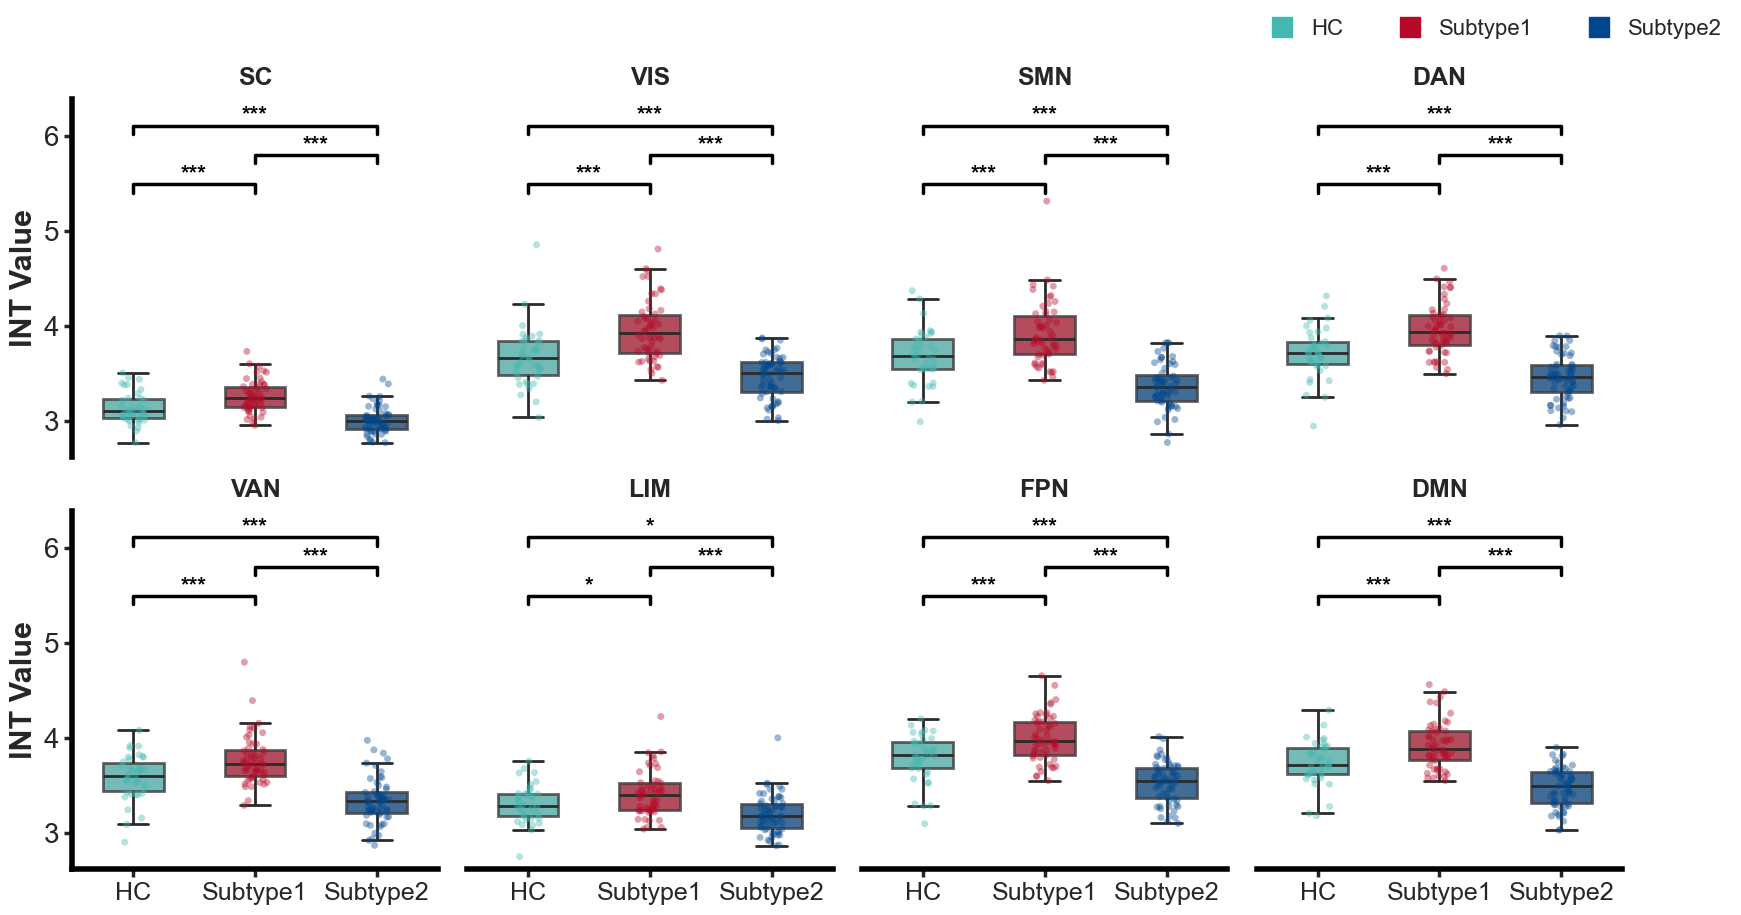


=== 绘图完成！图片已保存至: /Volumes/QC/INT/INT_BN246_HC135BP_MDD135BP_DZIII/INT_verify/Step2_8Net_INT_mean_Diff/Fig_Subtype_8NetINT_Diff_2x4.png ===


In [7]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
from statsmodels.formula.api import ols
from statsmodels.stats.multitest import multipletests
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.lines as mlines

# =========================================================
# 1. 数据读取与预处理
# =========================================================
path = "/Volumes/QC/INT/INT_BN246_HC135BP_MDD135BP_DZIII/INT_verify"
path_hc = path + '/HC_DZ_INT_8net.csv'
path_s1 = path +'/subtype1_DZ_INT_8net.csv'
path_s2 = path + '/subtype2_DZ_INT_8net.csv'

df_hc = pd.read_csv(path_hc)
df_s1 = pd.read_csv(path_s1)
df_s2 = pd.read_csv(path_s2)

# 添加组别标签
df_hc['group'] = 'HC'
df_s1['group'] = 'Subtype1'
df_s2['group'] = 'Subtype2'

# 合并大表并提取所需的列
df = pd.concat([df_hc, df_s1, df_s2], ignore_index=True)
networks = ['subcortical', 'Visual', 'Somatomotor', 'Dorsal_Attention',
            'Ventral_Attention', 'Limbic', 'Frontoparietal', 'Default']

# 定义用于显示在子图标题上的缩写名称
network_labels = ['SC', 'VIS', 'SMN', 'DAN', 'VAN', 'LIM', 'FPN', 'DMN']

df = df[['group', 'age', 'sex', 'mean_fd'] + networks].dropna()

print(f"总样本数: {len(df)} (HC: {len(df_hc)}, Subtype1: {len(df_s1)}, Subtype2: {len(df_s2)})")

# =========================================================
# 2. ANCOVA 主效应分析与事后两两比较计算
# =========================================================
results = []
pairwise_results = []
models = {}

for net in networks:
    # 模型构建：控制 age, sex, mean_fd
    formula = f'{net} ~ C(group) + age + C(sex) + mean_fd'
    model = ols(formula, data=df).fit()
    models[net] = model

    # 提取 ANOVA 表格 (主效应)
    anova_table = sm.stats.anova_lm(model, typ=2)
    p_group = anova_table.loc['C(group)', 'PR(>F)']
    f_group = anova_table.loc['C(group)', 'F']

    results.append({
        'Network': net,
        'F_value': f_group,
        'p_uncorrected': p_group
    })

    # 构建事后两两比较的 Contrast
    contrasts = {
        'HC_vs_Subtype1': 'C(group)[T.Subtype1] = 0',
        'HC_vs_Subtype2': 'C(group)[T.Subtype2] = 0',
        'Subtype1_vs_Subtype2': 'C(group)[T.Subtype1] - C(group)[T.Subtype2] = 0'
    }

    for comp_name, contrast_str in contrasts.items():
        t_test_res = model.t_test(contrast_str)
        p_val = t_test_res.pvalue.item() if hasattr(t_test_res.pvalue, 'item') else float(t_test_res.pvalue)
        t_val = t_test_res.tvalue.item() if hasattr(t_test_res.tvalue, 'item') else float(t_test_res.tvalue)
        pairwise_results.append({
            'Network': net,
            'Comparison': comp_name,
            't_value': t_val,
            'p_uncorrected': p_val
        })

# --- 主效应 FDR 校正 (8次检验) ---
results_df = pd.DataFrame(results)
_, p_fdr_main, _, _ = multipletests(results_df['p_uncorrected'], alpha=0.05, method='fdr_bh')
results_df['p_FDR'] = p_fdr_main
#results_df.to_csv(path + 'Step3_INT7Net_Diff/ANCOVA_8networks_INT_MainEffect_covFD.csv', index=False)

# --- 事后两两比较 FDR 校正 (全局24次检验) ---
pairwise_df = pd.DataFrame(pairwise_results)
_, p_fdr_pair, _, _ = multipletests(pairwise_df['p_uncorrected'], alpha=0.05, method='fdr_bh')
pairwise_df['p_FDR'] = p_fdr_pair

def get_stars(p):
    if p < 0.001: return '***'
    elif p < 0.01: return '**'
    elif p < 0.05: return '*'
    else: return 'ns'

pairwise_df['Significance'] = pairwise_df['p_FDR'].apply(get_stars)
#pairwise_df.to_csv(path + 'Step3_INT7Net_Diff/ANCOVA_8networks_INT_Pairwise_covFD.csv', index=False)

print("\n=== INT 主效应与两两比较分析完成！===")


# =========================================================
# 3. 画图数据准备 (回归年龄、性别、头动求残差)
# =========================================================
# 为了严格反映 ANCOVA 去除协变量后的纯净组间差异，绘图采用“残差 + 均值”
corrected_data = df.copy()
covariates = ['age', 'sex', 'mean_fd']

for net in networks:
    mask = df[[net] + covariates].notnull().all(axis=1)
    temp_df = df[mask]

    resid_formula = f'{net} ~ age + C(sex) + mean_fd'
    resid_model = ols(resid_formula, data=temp_df).fit()
    corrected_data.loc[mask, net] = resid_model.resid + temp_df[net].mean()

# 计算全局统一的 Y 轴范围
all_vals = []
for net in networks:
    all_vals.extend(corrected_data[net].dropna().values)
global_y_min = min(all_vals)
global_y_max = max(all_vals)
global_y_range = global_y_max - global_y_min

h_global = global_y_range * 0.035
step_global = global_y_range * 0.12 # 为多重对比堆叠星号预留空间

# 顶端预留 3层连线 的高度
unified_ylim_top = global_y_max + step_global * 3.5
unified_ylim_bottom = global_y_min - global_y_range * 0.05


# =========================================================
# 4. 2x4 分层绘图
# =========================================================
sns.set_theme(style='white', rc={'axes.facecolor': 'white', 'figure.facecolor': 'white'})

# 为三组设定颜色
group_order = ['HC', 'Subtype1', 'Subtype2']
group_palette = {'HC': '#42B8B1', 'Subtype1': '#B50A27', 'Subtype2': '#00478D'}

fig, axes = plt.subplots(nrows=2, ncols=4, figsize=(20, 10))
axes = axes.flatten()

for i, (net, label) in enumerate(zip(networks, network_labels)):
    ax = axes[i]

    df_net = corrected_data[['group', net]].dropna().copy()
    df_net.rename(columns={net: 'INT'}, inplace=True)

    # 绘制箱体图
    sns.boxplot(
        x='group', y='INT', data=df_net, order=group_order,
        palette=group_palette, width=0.5, showfliers=False,
        linewidth=2, boxprops={'alpha': 0.8, 'edgecolor': '#3C3B3D'},
        ax=ax
    )

    # 绘制散点图
    sns.stripplot(
        x='group', y='INT', data=df_net, order=group_order,
        dodge=False, alpha=0.4, jitter=True, size=5,
        palette=group_palette, legend=False, ax=ax
    )

    ax.set_xlim(-0.5, 2.5)

    # 1. 强制去除上边框和右边框
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

    # 设置子图标题
    ax.set_title(label, fontsize=18, fontweight='bold', pad=10)
    ax.set_xlabel('')

    # 统一设置全局共享的 Y 轴范围
    ax.set_ylim(unified_ylim_bottom, unified_ylim_top)

    # 2. 定制化 Y 轴：只在第一列保留
    if i % 4 == 0:
        ax.spines['left'].set_color('black')
        ax.spines['left'].set_linewidth(4)
        ax.spines['left'].set_visible(True)
        ax.set_ylabel('INT Value', fontsize=22, fontweight='bold')
        ax.tick_params(axis='y', labelsize=20, left=True, width=2.5, length=6)
    else:
        ax.spines['left'].set_visible(False)
        ax.set_ylabel('')
        ax.tick_params(axis='y', left=False, labelleft=False)

    # 3. 定制化 X 轴：只在第二行保留
    if i >= 4:
        ax.spines['bottom'].set_color('black')
        ax.spines['bottom'].set_linewidth(4)
        ax.spines['bottom'].set_visible(True)
        # 为防止重叠字号稍作调整
        ax.set_xticklabels(['HC', 'Subtype1', 'Subtype2'], fontsize=18)
        ax.tick_params(axis='x', bottom=True, labelbottom=True, width=2.5, length=6)
    else:
        ax.spines['bottom'].set_visible(False)
        ax.set_xticklabels([])
        ax.tick_params(axis='x', bottom=False, labelbottom=False)

    # 4. 绘制显著性连线和星号 (自适应堆叠)
    star_hc_s1 = pairwise_df[(pairwise_df['Network'] == net) & (pairwise_df['Comparison'] == 'HC_vs_Subtype1')]['Significance'].values[0]
    star_s1_s2 = pairwise_df[(pairwise_df['Network'] == net) & (pairwise_df['Comparison'] == 'Subtype1_vs_Subtype2')]['Significance'].values[0]
    star_hc_s2 = pairwise_df[(pairwise_df['Network'] == net) & (pairwise_df['Comparison'] == 'HC_vs_Subtype2')]['Significance'].values[0]

    current_y = global_y_max + h_global

    def add_bracket(x1, x2, y, text_star, current_ax):
        current_ax.plot([x1, x1, x2, x2], [y, y + h_global, y + h_global, y], lw=2.5, c='black')
        current_ax.text((x1 + x2) * .5, y + h_global, text_star, ha='center', va='bottom', color='black', fontsize=16, fontweight='bold')

    # 仅绘制有统计学意义的比较连线，逐层往上叠加
    if star_hc_s1 != 'ns':
        add_bracket(0, 1, current_y, star_hc_s1, ax)
        current_y += step_global

    if star_s1_s2 != 'ns':
        add_bracket(1, 2, current_y, star_s1_s2, ax)
        current_y += step_global

    if star_hc_s2 != 'ns':
        add_bracket(0, 2, current_y, star_hc_s2, ax)
        current_y += step_global

# =========================================================
# 5. 添加全局图例并保存
# =========================================================
hc_patch = mlines.Line2D([], [], color='#42B8B1', marker='s', linestyle='None', markersize=14, label='HC')
s1_patch = mlines.Line2D([], [], color='#B50A27', marker='s', linestyle='None', markersize=14, label='Subtype1')
s2_patch = mlines.Line2D([], [], color='#00478D', marker='s', linestyle='None', markersize=14, label='Subtype2')

fig.legend(handles=[hc_patch, s1_patch, s2_patch], loc='upper right', bbox_to_anchor=(0.96, 0.98),
           fontsize=16, frameon=False, ncol=3, handletextpad=0.3)

plt.subplots_adjust(hspace=0.15, wspace=0.08)

out_fig = path + '/Step2_8Net_INT_mean_Diff/Fig_Subtype_8NetINT_Diff_2x4.png'
plt.savefig(out_fig, dpi=300, bbox_inches='tight')
plt.show()

print(f'\n=== 绘图完成！图片已保存至: {out_fig} ===')

HC subtype1 subtype2  8各网络平均 INT  差异比较
按照 2x4 布局  （箱体不进行颜色填充）

In [14]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
from statsmodels.formula.api import ols
from statsmodels.stats.multitest import multipletests
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.lines as mlines

# =========================================================
# 1. 数据读取与预处理
# =========================================================
path = "/Volumes/QC/INT/INT_BN246_HC135BP_MDD135BP_DZIII/INT_verify/INT_covariate"
path_hc = path + '/HC_DZ_INT_8net.csv'
path_s1 = path +'/subtype1_DZ_INT_8net.csv'
path_s2 = path + '/subtype2_DZ_INT_8net.csv'

df_hc = pd.read_csv(path_hc)
df_s1 = pd.read_csv(path_s1)
df_s2 = pd.read_csv(path_s2)

# 添加组别标签
df_hc['group'] = 'HC'
df_s1['group'] = 'Subtype1'
df_s2['group'] = 'Subtype2'

# 合并大表并提取所需的列
df = pd.concat([df_hc, df_s1, df_s2], ignore_index=True)
networks = ['subcortical', 'Visual', 'Somatomotor', 'Dorsal_Attention',
            'Ventral_Attention', 'Limbic', 'Frontoparietal', 'Default']

# 定义用于显示在子图标题上的缩写名称
network_labels = ['SC', 'VIS', 'SMN', 'DAN', 'VAN', 'LIM', 'FPN', 'DMN']

df = df[['group', 'age', 'sex', 'mean_fd'] + networks].dropna()

print(f"总样本数: {len(df)} (HC: {len(df_hc)}, Subtype1: {len(df_s1)}, Subtype2: {len(df_s2)})")

# =========================================================
# 2. ANCOVA 主效应分析与事后两两比较计算
# =========================================================
results = []
pairwise_results = []
models = {}

for net in networks:
    # 模型构建：控制 age, sex, mean_fd
    formula = f'{net} ~ C(group) + age + C(sex) + mean_fd'
    model = ols(formula, data=df).fit()
    models[net] = model

    # 提取 ANOVA 表格 (主效应)
    anova_table = sm.stats.anova_lm(model, typ=2)
    p_group = anova_table.loc['C(group)', 'PR(>F)']
    f_group = anova_table.loc['C(group)', 'F']

    results.append({
        'Network': net,
        'F_value': f_group,
        'p_uncorrected': p_group
    })

    # 构建事后两两比较的 Contrast
    contrasts = {
        'HC_vs_Subtype1': 'C(group)[T.Subtype1] = 0',
        'HC_vs_Subtype2': 'C(group)[T.Subtype2] = 0',
        'Subtype1_vs_Subtype2': 'C(group)[T.Subtype1] - C(group)[T.Subtype2] = 0'
    }

    for comp_name, contrast_str in contrasts.items():
        t_test_res = model.t_test(contrast_str)
        p_val = t_test_res.pvalue.item() if hasattr(t_test_res.pvalue, 'item') else float(t_test_res.pvalue)
        t_val = t_test_res.tvalue.item() if hasattr(t_test_res.tvalue, 'item') else float(t_test_res.tvalue)
        pairwise_results.append({
            'Network': net,
            'Comparison': comp_name,
            't_value': t_val,
            'p_uncorrected': p_val
        })

# --- 主效应 FDR 校正 (8次检验) ---
results_df = pd.DataFrame(results)
_, p_fdr_main, _, _ = multipletests(results_df['p_uncorrected'], alpha=0.05, method='fdr_bh')
results_df['p_FDR'] = p_fdr_main

# --- 事后两两比较 FDR 校正 (全局24次检验) ---
pairwise_df = pd.DataFrame(pairwise_results)
_, p_fdr_pair, _, _ = multipletests(pairwise_df['p_uncorrected'], alpha=0.05, method='fdr_bh')
pairwise_df['p_FDR'] = p_fdr_pair

def get_stars(p):
    if p < 0.001: return '***'
    elif p < 0.01: return '**'
    elif p < 0.05: return '*'
    else: return 'ns'

pairwise_df['Significance'] = pairwise_df['p_FDR'].apply(get_stars)

print("\n=== INT 主效应与两两比较分析完成！===")


# =========================================================
# 3. 画图数据准备 (回归年龄、性别、头动求残差)
# =========================================================
corrected_data = df.copy()
covariates = ['age', 'sex', 'mean_fd']

for net in networks:
    mask = df[[net] + covariates].notnull().all(axis=1)
    temp_df = df[mask]

    resid_formula = f'{net} ~ age + C(sex) + mean_fd'
    resid_model = ols(resid_formula, data=temp_df).fit()
    corrected_data.loc[mask, net] = resid_model.resid + temp_df[net].mean()

# 计算全局统一的 Y 轴范围
all_vals = []
for net in networks:
    all_vals.extend(corrected_data[net].dropna().values)
global_y_min = min(all_vals)
global_y_max = max(all_vals)
global_y_range = global_y_max - global_y_min

h_global = global_y_range * 0.035
step_global = global_y_range * 0.12 # 为多重对比堆叠星号预留空间

unified_ylim_top = global_y_max + step_global * 3.5
unified_ylim_bottom = global_y_min - global_y_range * 0.05


# =========================================================
# 4. 2x4 分层绘图
# =========================================================
sns.set_theme(style='white', rc={'axes.facecolor': 'white', 'figure.facecolor': 'white'})

# 为三组设定颜色
group_order = ['HC', 'Subtype1', 'Subtype2']
group_palette = {'HC': '#9a9da1', 'Subtype1': '#B50A27', 'Subtype2': '#00478D'}

fig, axes = plt.subplots(nrows=2, ncols=4, figsize=(20, 10))
axes = axes.flatten()

for i, (net, label) in enumerate(zip(networks, network_labels)):
    ax = axes[i]

    df_net = corrected_data[['group', net]].dropna().copy()
    df_net.rename(columns={net: 'INT'}, inplace=True)

    # -------------------【核心修改区域开始】-------------------
    # 1. 绘制基础箱体图 (先正常绘制)
    sns.boxplot(
        x='group', y='INT', data=df_net, order=group_order,
        palette=group_palette, width=0.5, showfliers=False,
        linewidth=2, ax=ax
    )

    # 获取当前三组对应的颜色序列
    colors = [group_palette[g] for g in group_order]

    # 2. 修改箱体自身：将填充变透明，边框改为对应的颜色
    # 兼容 Seaborn >= 0.13 (使用 ax.patches) 和 < 0.13 (使用 ax.artists)
    for j, patch in enumerate(ax.patches):
        if hasattr(patch, 'set_facecolor'):
            patch.set_facecolor('none')  # 变成完全空白透明
            patch.set_edgecolor(colors[j % len(colors)]) # 线条颜色按组赋值

    for j, artist in enumerate(ax.artists):
        artist.set_facecolor('none')
        artist.set_edgecolor(colors[j % len(colors)])

    # 3. 修改箱体的附属线条：包括中位线(Median)、上下须(Whiskers)、须盖板(Caps)
    # 没有 fliers 的情况下，每个箱体有 5 条线。我们按照比例映射线条颜色
    if len(ax.lines) > 0 and len(ax.lines) % len(group_order) == 0:
        lines_per_box = len(ax.lines) // len(group_order)
        for j, line in enumerate(ax.lines):
            group_idx = j // lines_per_box
            line.set_color(colors[group_idx])
            line.set_linewidth(2)
    # -------------------【核心修改区域结束】-------------------

    # 绘制散点图 (点会带有 alpha 透明度并铺在对应的空白箱体上方)
    sns.stripplot(
        x='group', y='INT', data=df_net, order=group_order,
        dodge=False, alpha=0.4, jitter=True, size=5,
        palette=group_palette, legend=False, ax=ax
    )

    ax.set_xlim(-0.5, 2.5)

    # 强制去除上边框和右边框
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

    # 设置子图标题
    ax.set_title(label, fontsize=18, fontweight='bold', pad=10)
    ax.set_xlabel('')

    # 统一设置全局共享的 Y 轴范围
    ax.set_ylim(unified_ylim_bottom, unified_ylim_top)

    # 定制化 Y 轴：只在第一列保留
    if i % 4 == 0:
        ax.spines['left'].set_color('black')
        ax.spines['left'].set_linewidth(4)
        ax.spines['left'].set_visible(True)
        ax.set_ylabel('INT Value', fontsize=22, fontweight='bold')
        ax.tick_params(axis='y', labelsize=20, left=True, width=2.5, length=6)
    else:
        ax.spines['left'].set_visible(False)
        ax.set_ylabel('')
        ax.tick_params(axis='y', left=False, labelleft=False)

    # 定制化 X 轴：只在第二行保留
    if i >= 4:
        ax.spines['bottom'].set_color('black')
        ax.spines['bottom'].set_linewidth(4)
        ax.spines['bottom'].set_visible(True)
        ax.set_xticklabels(['HC', 'Subtype1', 'Subtype2'], fontsize=18)
        ax.tick_params(axis='x', bottom=True, labelbottom=True, width=2.5, length=6)
    else:
        ax.spines['bottom'].set_visible(False)
        ax.set_xticklabels([])
        ax.tick_params(axis='x', bottom=False, labelbottom=False)

    # 绘制显著性连线和星号 (自适应堆叠)
    star_hc_s1 = pairwise_df[(pairwise_df['Network'] == net) & (pairwise_df['Comparison'] == 'HC_vs_Subtype1')]['Significance'].values[0]
    star_s1_s2 = pairwise_df[(pairwise_df['Network'] == net) & (pairwise_df['Comparison'] == 'Subtype1_vs_Subtype2')]['Significance'].values[0]
    star_hc_s2 = pairwise_df[(pairwise_df['Network'] == net) & (pairwise_df['Comparison'] == 'HC_vs_Subtype2')]['Significance'].values[0]

    current_y = global_y_max + h_global

    def add_bracket(x1, x2, y, text_star, current_ax):
        current_ax.plot([x1, x1, x2, x2], [y, y + h_global, y + h_global, y], lw=2.5, c='black')
        current_ax.text((x1 + x2) * .5, y + h_global, text_star, ha='center', va='bottom', color='black', fontsize=16, fontweight='bold')

    if star_hc_s1 != 'ns':
        add_bracket(0, 1, current_y, star_hc_s1, ax)
        current_y += step_global

    if star_s1_s2 != 'ns':
        add_bracket(1, 2, current_y, star_s1_s2, ax)
        current_y += step_global

    if star_hc_s2 != 'ns':
        add_bracket(0, 2, current_y, star_hc_s2, ax)
        current_y += step_global

# =========================================================
# 5. 添加全局图例并保存
# =========================================================
hc_patch = mlines.Line2D([], [], color='#9a9da1', marker='s', linestyle='None', markersize=14, label='HC')
s1_patch = mlines.Line2D([], [], color='#B50A27', marker='s', linestyle='None', markersize=14, label='Subtype1')
s2_patch = mlines.Line2D([], [], color='#00478D', marker='s', linestyle='None', markersize=14, label='Subtype2')

fig.legend(handles=[hc_patch, s1_patch, s2_patch], loc='upper right', bbox_to_anchor=(0.96, 0.98),
           fontsize=16, frameon=False, ncol=3, handletextpad=0.3)

plt.subplots_adjust(hspace=0.15, wspace=0.08)

out_fig = path + '/Step2_8Net_INT_mean_Diff/Fig_Subtype_8NetINT_Diff_2x4_Hollow.png'
plt.savefig(out_fig, dpi=300, bbox_inches='tight')
plt.show()

print(f'\n=== 绘图完成！图片已保存至: {out_fig} ===')

总样本数: 151 (HC: 38, Subtype1: 50, Subtype2: 63)

=== INT 主效应与两两比较分析完成！===


/var/folders/dh/dmftg40j21j249nqf2z5v2nh0000gn/T/ipykernel_7122/463540074.py:151: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/var/folders/dh/dmftg40j21j249nqf2z5v2nh0000gn/T/ipykernel_7122/463540074.py:182: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.stripplot(
/var/folders/dh/dmftg40j21j249nqf2z5v2nh0000gn/T/ipykernel_7122/463540074.py:151: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/var/folders/dh/dmftg40j21j249nqf2z5v2nh0000gn/T/ipykernel_7122/463540074.py:182: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and


=== 绘图完成！图片已保存至: /Volumes/QC/INT/INT_BN246_HC135BP_MDD135BP_DZIII/INT_verify/INT_covariate/Step2_8Net_INT_mean_Diff/Fig_Subtype_8NetINT_Diff_2x4_Hollow.png ===


/var/folders/dh/dmftg40j21j249nqf2z5v2nh0000gn/T/ipykernel_7122/463540074.py:262: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


Variance 画图

In [17]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
from scipy.stats import zscore
from nilearn.conftest import matplotlib
from statsmodels.formula.api import ols
from statsmodels.stats.multitest import multipletests
import matplotlib.pyplot as plt
import seaborn as sns

# 如果不需要在独立窗口弹出图片，可以使用 Agg 后端
matplotlib.use('Agg')

# 统一定义输出基础路径，方便后续拼写文件名
base_dir = '/Volumes/QC/INT/INT_BN246_HC135BP_MDD135BP_DZIII/INT_verify/INT_covariate/Step4_Variance_Diff/'

# =========================================================
# 1. 读取文件与数据合并
# =========================================================
df_hc = pd.read_csv(base_dir + 'HC_INT_7net_variance.csv')
df_s1 = pd.read_csv(base_dir + 'subtype1_INT_7net_variance.csv')
df_s2 = pd.read_csv(base_dir + 'subtype2_INT_7net_variance.csv')


# 提取需要的列 (假设 HC 文件里的 age/sex 列名已经是 age, sex)
df_hc = df_hc[['subID', 'mean_fd', 'age', 'sex', 'variance']]
df_s1 = df_s1[['subID', 'mean_fd', 'age', 'sex', 'variance']]
df_s2 = df_s2[['subID', 'mean_fd', 'age', 'sex', 'variance']]

df_hc['group'] = 'HC'
df_s1['group'] = 'Subtype1'
df_s2['group'] = 'Subtype2'

# 合并得到原始全量数据
df_raw = pd.concat([df_hc, df_s1, df_s2], ignore_index=True)
df_raw = df_raw[['group', 'age', 'sex', 'variance', 'mean_fd']].dropna()

# =========================================================
# 2. 异常值剔除处理 (按 group 分组计算 > 3 SD)
# =========================================================
# 按组计算 Z-score (自由度 ddof=1)
df_raw['variance_zscore'] = df_raw.groupby('group')['variance'].transform(lambda x: zscore(x, ddof=1))

# 设定 3 个标准差为阈值
threshold = 3.0

# 提取绝对值小于等于 3 的数据作为清洗后数据
df_clean = df_raw[np.abs(df_raw['variance_zscore']) <= threshold].copy()

print("========== 数据异常值检查 ==========")
print(f"原始数据样本量: {len(df_raw)}")
print(f"清洗后数据样本量: {len(df_clean)}")
print(f"剔除的异常值数量: {len(df_raw) - len(df_clean)}")
print("====================================\n")


# =========================================================
# 3. 核心统计与绘图函数封装
# =========================================================
def run_analysis_and_plot(df, suffix, title_note):
    """
    执行 ANCOVA, 事后两两比较, 并绘制箱线图
    :param df: 输入的数据框 (df_raw 或 df_clean)
    :param suffix: 输出文件名的后缀 ('Raw' 或 'Clean')
    :param title_note: 图片标题的额外注释 (如果不需要显示标题可在下方代码中注销)
    """
    print(f"开始处理: 【{suffix}】 组数据分析")

    # 1. ANCOVA 主效应模型构建
    model = ols('variance ~ C(group) + age + C(sex) + mean_fd', data=df).fit()

    # 计算协方差分析表 (主效应) 并保存
    anova_table = sm.stats.anova_lm(model, typ=2)
    anova_csv_path = base_dir + f'Diff_variance_ANCOVA_MainEffect_covFD_{suffix}.csv'
    anova_table.to_csv(anova_csv_path)

    # 2. 事后检验分析 (Pairwise Comparisons) 与 FDR 校正
    pairwise_results = []
    contrasts = {
        'HC_vs_Subtype1': 'C(group)[T.Subtype1] = 0',
        'HC_vs_Subtype2': 'C(group)[T.Subtype2] = 0',
        'Subtype1_vs_Subtype2': 'C(group)[T.Subtype1] - C(group)[T.Subtype2] = 0'
    }

    for comp_name, contrast_str in contrasts.items():
        t_test_res = model.t_test(contrast_str)
        p_val = t_test_res.pvalue.item() if hasattr(t_test_res.pvalue, 'item') else float(t_test_res.pvalue)
        t_val = t_test_res.tvalue.item() if hasattr(t_test_res.tvalue, 'item') else float(t_test_res.tvalue)
        pairwise_results.append({
            'Comparison': comp_name,
            't_value': t_val,
            'p_uncorrected': p_val
        })

    pairwise_df = pd.DataFrame(pairwise_results)

    # FDR 校正
    _, p_fdr_pair, _, _ = multipletests(pairwise_df['p_uncorrected'], alpha=0.05, method='fdr_bh')
    pairwise_df['p_FDR'] = p_fdr_pair

    def get_stars(p):
        if p < 0.001:
            return '***'
        elif p < 0.01:
            return '**'
        elif p < 0.05:
            return '*'
        else:
            return 'ns'

    pairwise_df['Significance'] = pairwise_df['p_FDR'].apply(get_stars)
    pairwise_csv_path = base_dir + f'Diff_variance_ANCOVA_Pairwise_covFD_{suffix}.csv'
    #pairwise_df.to_csv(pairwise_csv_path, index=False)

    print(f"[{suffix}] 事后两两比较 (FDR 校正) 结果:")
    print(pairwise_df)
    print("-" * 40)

    # =========================================================
    # 3. 绘制箱体填充为空白无色、线条赋指定颜色的箱体图
    # =========================================================
    plt.figure(figsize=(8, 6))

    # 设置画板背景为白色
    sns.set_theme(style='white', rc={'axes.facecolor': 'white', 'figure.facecolor': 'white'})

    # 自定义配色字典
    custom_palette = {'HC': '#9a9da1', 'Subtype1': '#B50A27', 'Subtype2': '#00478D'}
    groups_order = ['HC', 'Subtype1', 'Subtype2']

    # 绘制箱线图
    ax = sns.boxplot(
        x='group',
        y='variance',
        data=df,
        order=groups_order,
        palette=custom_palette,
        width=0.5,
        showfliers=False,
        linewidth=1.7,
        boxprops={'facecolor': 'none', 'alpha': 0.8}
    )

    # 将箱体的外框、须线、盖帽、中位数线统一修改为对应组的专属配色
    for i, group_name in enumerate(groups_order):
        group_color = custom_palette[group_name]

        # 1. 对应箱体自身的边框（box 边缘）
        if i < len(ax.patches):
            ax.patches[i].set_facecolor('none')       # 确保箱体为空白无色填充
            ax.patches[i].set_edgecolor(group_color)  # 将外框线修改为专属颜色
            ax.patches[i].set_linewidth(3)

        # 兼容部分版本（补充判断）
        if hasattr(ax, 'artists') and i < len(ax.artists):
            ax.artists[i].set_facecolor('none')
            ax.artists[i].set_edgecolor(group_color)
            ax.artists[i].set_linewidth(3)

        # 2. 对应箱体的内部线条（whiskers, caps, medians 依次为每组 5 条线）
        for j in range(5):
            line_idx = i * 5 + j
            if line_idx < len(ax.lines):
                ax.lines[line_idx].set_color(group_color)
                ax.lines[line_idx].set_linewidth(4)

    # 绘制散点图
    sns.stripplot(
        x='group',
        y='variance',
        data=df,
        order=groups_order,
        palette=custom_palette,
        alpha=0.8,
        size=6,
        jitter=True,
        ax=ax
    )

    # 设置四周边框（上下左右轴）为黑色，线条加粗
    for spine in ax.spines.values():
        spine.set_edgecolor('black')
        spine.set_linewidth(3.0)
        spine.set_visible(True)

    y_max = df['variance'].max()
    y_min = df['variance'].min()
    y_range = y_max - y_min

    # 连线的动态高度步长和拐角小尾巴长度
    step = 0.08 * y_range
    h = 0.02 * y_range
    current_y = y_max + 0.05 * y_range

    star_hc_s1 = pairwise_df[pairwise_df['Comparison'] == 'HC_vs_Subtype1']['Significance'].values[0]
    star_s1_s2 = pairwise_df[pairwise_df['Comparison'] == 'Subtype1_vs_Subtype2']['Significance'].values[0]
    star_hc_s2 = pairwise_df[pairwise_df['Comparison'] == 'HC_vs_Subtype2']['Significance'].values[0]

    def add_bracket(x1, x2, y, text_star):
        plt.plot([x1, x1, x2, x2], [y, y + h, y + h, y], lw=2.5, color='black')
        # 按照提供的代码代理，此处文本高度置于 y
        plt.text((x1 + x2) * 0.5, y, text_star, ha='center', va='bottom', color='black', fontsize=18, fontweight='bold')

    # 动态堆叠画线逻辑：只有显著的 ('ns' 以外) 才画线
    if star_hc_s1 != 'ns':
        add_bracket(0, 1, current_y, star_hc_s1)
        current_y += step

    if star_s1_s2 != 'ns':
        add_bracket(1, 2, current_y, star_s1_s2)
        current_y += step

    if star_hc_s2 != 'ns':
        add_bracket(0, 2, current_y, star_hc_s2)
        current_y += step

    # 自动调整 y 轴范围，为顶部的连线留出空间
    plt.ylim(y_min - 0.05 * y_range, current_y + 0.1 * y_range)

    # 图表标签与字体大小调整
    plt.ylabel('', fontsize=14)
    plt.xlabel('', fontsize=14)
    plt.xticks(fontsize=26)

    # ----------------------------------------------------
    # 这里修改：针对剔除异常值后的图片，定制 Y 轴刻度
    # ----------------------------------------------------
    if suffix == 'Clean':
        plt.yticks([0.0, 0.1, 0.2, 0.3], fontsize=26)
    else:
        plt.yticks([0.0, 0.2, 0.4, 0.6],fontsize=26)
    # ----------------------------------------------------

    # 增加 title 注释，如果不需要可以注释掉这行
    #plt.title(f'{title_note}', fontsize=16, pad=20)

    plt.tight_layout()

    # 保存并展示图片
    img_save_path = base_dir + f'Fig_Diff_variance_ANCOVA_Stars_covFD_{suffix}.png'
    plt.savefig(img_save_path, dpi=300, bbox_inches='tight')
    plt.close()  # 必须关闭当前图，否则两张图会叠加在同一个画布上

    print(f"=== [{suffix}] 绘图完成！图片已保存至: {img_save_path} ===\n")


# =========================================================
# 4. 运行分析
# =========================================================
# 第一次运行：原始数据 (Raw)
run_analysis_and_plot(df_raw, suffix='Raw', title_note='[Original Data]')

# 第二次运行：剔除 >3SD 后的数据 (Clean)
run_analysis_and_plot(df_clean, suffix='Clean', title_note='[Outliers > 3SD Removed]')

print("所有步骤执行完毕！两套结果（原始的与剔除异常值的）均已分别保存。")

========== 数据异常值检查 ==========
原始数据样本量: 151
清洗后数据样本量: 148
剔除的异常值数量: 3

开始处理: 【Raw】 组数据分析
[Raw] 事后两两比较 (FDR 校正) 结果:
             Comparison   t_value  p_uncorrected         p_FDR Significance
0        HC_vs_Subtype1  4.278148   3.404383e-05  5.106575e-05          ***
1        HC_vs_Subtype2 -1.828789   6.948603e-02  6.948603e-02           ns
2  Subtype1_vs_Subtype2  6.834850   2.113273e-10  6.339819e-10          ***
----------------------------------------


/var/folders/dh/dmftg40j21j249nqf2z5v2nh0000gn/T/ipykernel_7122/3400215909.py:132: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.boxplot(
/var/folders/dh/dmftg40j21j249nqf2z5v2nh0000gn/T/ipykernel_7122/3400215909.py:168: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.stripplot(


=== [Raw] 绘图完成！图片已保存至: /Volumes/QC/INT/INT_BN246_HC135BP_MDD135BP_DZIII/INT_verify/INT_covariate/Step4_Variance_Diff/Fig_Diff_variance_ANCOVA_Stars_covFD_Raw.png ===

开始处理: 【Clean】 组数据分析
[Clean] 事后两两比较 (FDR 校正) 结果:
             Comparison   t_value  p_uncorrected         p_FDR Significance
0        HC_vs_Subtype1  4.774728   4.429228e-06  6.643843e-06          ***
1        HC_vs_Subtype2 -1.789852   7.560884e-02  7.560884e-02           ns
2  Subtype1_vs_Subtype2  7.366562   1.309355e-11  3.928066e-11          ***
----------------------------------------


/var/folders/dh/dmftg40j21j249nqf2z5v2nh0000gn/T/ipykernel_7122/3400215909.py:132: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.boxplot(
/var/folders/dh/dmftg40j21j249nqf2z5v2nh0000gn/T/ipykernel_7122/3400215909.py:168: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.stripplot(


=== [Clean] 绘图完成！图片已保存至: /Volumes/QC/INT/INT_BN246_HC135BP_MDD135BP_DZIII/INT_verify/INT_covariate/Step4_Variance_Diff/Fig_Diff_variance_ANCOVA_Stars_covFD_Clean.png ===

所有步骤执行完毕！两套结果（原始的与剔除异常值的）均已分别保存。


Range 基于 Network的 range

In [20]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
from scipy.stats import zscore
from statsmodels.formula.api import ols
from statsmodels.stats.multitest import multipletests
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib

# 若不需要在本地直接弹窗，可以使用 Agg 后端
matplotlib.use('Agg')

# ==========================================
# 1. 读取数据
# ==========================================
# 建议修改为您实际的本地 base_dir 路径
base_dir = '/Volumes/QC/INT/INT_BN246_HC135BP_MDD135BP_DZIII/INT_verify/INT_covariate/Step5_Range_Diff/'
df_hc = pd.read_csv(base_dir + 'HC_DZ_INT_8net_Range.csv')
df1 = pd.read_csv(base_dir + 'subtype1_DZ_INT_8net_Range.csv')
df2 = pd.read_csv(base_dir + 'subtype2_DZ_INT_8net_Range.csv')

# ==========================================
# 2. 添加组别标签并合并数据
# ==========================================
df_hc['group'] = 'HC'
df1['group'] = 'Subtype1'
df2['group'] = 'Subtype2'

# 将三组数据合并，并删除含有缺失值的行
df_raw = pd.concat([df_hc, df1, df2], ignore_index=True)
df_raw = df_raw.dropna(subset=['difference', 'age', 'sex', 'mean_fd'])

# 为了在模型中有明确的对比基准，我们将 group 转换为有顺序的分类变量
df_raw['group'] = pd.Categorical(df_raw['group'], categories=['HC', 'Subtype1', 'Subtype2'])

# =========================================================
# 3. 异常值剔除处理 (按 group 分组计算 > 3 SD)
# =========================================================
# 按组计算 Z-score (自由度 ddof=1)
df_raw['difference_zscore'] = df_raw.groupby('group')['difference'].transform(lambda x: zscore(x, ddof=1))

# 设定 3 个标准差为阈值
threshold = 3.0

# 提取绝对值小于等于 3 的数据作为清洗后数据
df_clean = df_raw[np.abs(df_raw['difference_zscore']) <= threshold].copy()

print("========== 数据异常值检查 ==========")
print(f"原始数据样本量: {len(df_raw)}")
print(f"清洗后数据样本量: {len(df_clean)}")
print(f"剔除的异常值数量: {len(df_raw) - len(df_clean)}")
print("====================================\n")


# =========================================================
# 4. 核心统计与绘图函数封装
# =========================================================
def run_analysis_and_plot(df_input, suffix):
    print(f"\n开始处理: 【{suffix}】 组数据分析")

    # --- 统计检验：协方差分析 (ANCOVA) 主效应 ---
    model = ols('difference ~ C(group, Treatment("HC")) + age + C(sex) + mean_fd', data=df_input).fit()
    anova_table = sm.stats.anova_lm(model, typ=2)
    print(f"[{suffix}] ANCOVA 主效应统计结果:")
    print(anova_table)

    # 保存主效应结果
    anova_table.to_csv(base_dir + f'Diff_difference_ANCOVA_MainEffect_covFD_{suffix}.csv')

    # --- 事后检验 (Pairwise Comparisons) 与 FDR 校正 ---
    pairwise_results = []
    contrasts = {
        'HC_vs_Subtype1': 'C(group, Treatment("HC"))[T.Subtype1] = 0',
        'HC_vs_Subtype2': 'C(group, Treatment("HC"))[T.Subtype2] = 0',
        'Subtype1_vs_Subtype2': 'C(group, Treatment("HC"))[T.Subtype1] - C(group, Treatment("HC"))[T.Subtype2] = 0'
    }

    for comp_name, contrast_str in contrasts.items():
        t_test_res = model.t_test(contrast_str)
        p_val = t_test_res.pvalue.item() if hasattr(t_test_res.pvalue, 'item') else float(t_test_res.pvalue)
        t_val = t_test_res.tvalue.item() if hasattr(t_test_res.tvalue, 'item') else float(t_test_res.tvalue)
        pairwise_results.append({
            'Comparison': comp_name,
            't_value': t_val,
            'p_uncorrected': p_val
        })

    pairwise_df = pd.DataFrame(pairwise_results)

    # FDR 校正
    _, p_fdr, _, _ = multipletests(pairwise_df['p_uncorrected'], alpha=0.05, method='fdr_bh')
    pairwise_df['p_FDR'] = p_fdr

    def get_stars(p):
        if p < 0.001: return '***'
        elif p < 0.01: return '**'
        elif p < 0.05: return '*'
        else: return 'ns'

    pairwise_df['stars'] = pairwise_df['p_FDR'].apply(get_stars)
    print(f"[{suffix}] 事后两两比较 (FDR 校正):")
    print(pairwise_df)

    # 保存事后比较结果
    pairwise_df.to_csv(base_dir + f'Diff_difference_ANCOVA_Pairwise_covFD_{suffix}.csv', index=False)

    # --- 绘制箱体填充为空白无色、线条赋指定颜色的箱体图 ---
    plt.figure(figsize=(8, 6))
    sns.set_theme(style='white', rc={'axes.facecolor': 'white', 'figure.facecolor': 'white'})

    custom_palette = {'HC': '#9a9da1', 'Subtype1': '#B50A27', 'Subtype2': '#00478D'}
    groups_order = ['HC', 'Subtype1', 'Subtype2']

    ax = sns.boxplot(
        x='group',
        y='difference',
        data=df_input,
        order=groups_order,
        palette=custom_palette,
        width=0.5,
        showfliers=False,
        linewidth=1.7,
        boxprops={'facecolor': 'none', 'alpha': 0.8}
    )

    for i, group_name in enumerate(groups_order):
        group_color = custom_palette[group_name]

        if i < len(ax.patches):
            ax.patches[i].set_facecolor('none')
            ax.patches[i].set_edgecolor(group_color)
            ax.patches[i].set_linewidth(3)

        if hasattr(ax, 'artists') and i < len(ax.artists):
            ax.artists[i].set_facecolor('none')
            ax.artists[i].set_edgecolor(group_color)
            ax.artists[i].set_linewidth(3)

        for j in range(5):
            line_idx = i * 5 + j
            if line_idx < len(ax.lines):
                ax.lines[line_idx].set_color(group_color)
                ax.lines[line_idx].set_linewidth(4)

    sns.stripplot(
        x='group',
        y='difference',
        data=df_input,
        order=groups_order,
        palette=custom_palette,
        alpha=0.8,
        size=6,
        jitter=True,
        ax=ax
    )

    for spine in ax.spines.values():
        spine.set_edgecolor('black')
        spine.set_linewidth(3.0)
        spine.set_visible(True)

    y_max = df_input['difference'].max()
    y_min = df_input['difference'].min()
    y_range = y_max - y_min

    step = 0.08 * y_range
    h = 0.02 * y_range
    current_y = y_max + 0.05 * y_range

    star_hc_s1 = pairwise_df[pairwise_df['Comparison'] == 'HC_vs_Subtype1']['stars'].values[0]
    star_s1_s2 = pairwise_df[pairwise_df['Comparison'] == 'Subtype1_vs_Subtype2']['stars'].values[0]
    star_hc_s2 = pairwise_df[pairwise_df['Comparison'] == 'HC_vs_Subtype2']['stars'].values[0]

    def add_bracket(x1, x2, y, text_star):
        plt.plot([x1, x1, x2, x2], [y, y + h, y + h, y], lw=2.5, color='black')
        plt.text((x1 + x2) * 0.5, y, text_star, ha='center', va='bottom', color='black', fontsize=18, fontweight='bold')

    if star_hc_s1 != 'ns':
        add_bracket(0, 1, current_y, star_hc_s1)
        current_y += step

    if star_s1_s2 != 'ns':
        add_bracket(1, 2, current_y, star_s1_s2)
        current_y += step

    if star_hc_s2 != 'ns':
        add_bracket(0, 2, current_y, star_hc_s2)
        current_y += step

    plt.ylim(y_min - 0.05 * y_range, current_y + 0.1 * y_range)

    plt.ylabel('', fontsize=20, fontweight='bold')
    plt.xlabel('', fontsize=14)
    plt.xticks(fontsize=26)

    # ====================================================
    # 根据 Suffix 动态调整 Y 轴的刻度数值
    # ====================================================
    if suffix == 'Clean':
        plt.yticks([0.5, 1.0, 1.5,2.0], fontsize=24)
    elif suffix == 'Raw':
        plt.yticks([0.5, 1.5, 2.5], fontsize=24)
    else:
        plt.yticks(fontsize=24)
    # ====================================================

    plt.tight_layout()

    save_path = base_dir + f'Fig_Range_ANCOVA_{suffix}.png'
    plt.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.close()

    print(f"绘图完成！已保存至 {save_path}")

# =========================================================
# 5. 执行分析
# =========================================================
# 第一次运行：未处理的原始数据
run_analysis_and_plot(df_raw, suffix='Raw')

# 第二次运行：剔除了 >3SD 的干净数据
run_analysis_and_plot(df_clean, suffix='Clean')

print("\n所有步骤执行完毕！两套结果（原始的与剔除异常值的）均已分别保存。")

/var/folders/dh/dmftg40j21j249nqf2z5v2nh0000gn/T/ipykernel_7122/1262785496.py:41: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df_raw['difference_zscore'] = df_raw.groupby('group')['difference'].transform(lambda x: zscore(x, ddof=1))
/var/folders/dh/dmftg40j21j249nqf2z5v2nh0000gn/T/ipykernel_7122/1262785496.py:115: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.boxplot(
/var/folders/dh/dmftg40j21j249nqf2z5v2nh0000gn/T/ipykernel_7122/1262785496.py:146: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.stripplot(


========== 数据异常值检查 ==========
原始数据样本量: 151
清洗后数据样本量: 149
剔除的异常值数量: 2


开始处理: 【Raw】 组数据分析
[Raw] ANCOVA 主效应统计结果:
                             sum_sq     df          F        PR(>F)
C(group, Treatment("HC"))  2.582524    2.0  24.218499  8.415178e-10
C(sex)                     1.700592    1.0  31.895771  8.310545e-08
age                        0.040196    1.0   0.753903  3.866781e-01
mean_fd                    0.221405    1.0   4.152600  4.338882e-02
Residual                   7.730991  145.0        NaN           NaN
[Raw] 事后两两比较 (FDR 校正):
             Comparison   t_value  p_uncorrected         p_FDR stars
0        HC_vs_Subtype1  4.142010   5.822394e-05  8.733591e-05   ***
1        HC_vs_Subtype2 -2.034081   4.376659e-02  4.376659e-02     *
2  Subtype1_vs_Subtype2  6.903338   1.471305e-10  4.413916e-10   ***
绘图完成！已保存至 /Volumes/QC/INT/INT_BN246_HC135BP_MDD135BP_DZIII/INT_verify/INT_covariate/Step5_Range_Diff/Fig_Range_ANCOVA_Raw.png

开始处理: 【Clean】 组数据分析
[Clean] ANCOVA 主效应统计结果:
           

/var/folders/dh/dmftg40j21j249nqf2z5v2nh0000gn/T/ipykernel_7122/1262785496.py:115: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.boxplot(
/var/folders/dh/dmftg40j21j249nqf2z5v2nh0000gn/T/ipykernel_7122/1262785496.py:146: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.stripplot(


绘图完成！已保存至 /Volumes/QC/INT/INT_BN246_HC135BP_MDD135BP_DZIII/INT_verify/INT_covariate/Step5_Range_Diff/Fig_Range_ANCOVA_Clean.png

所有步骤执行完毕！两套结果（原始的与剔除异常值的）均已分别保存。


QIDS 亚型间差异比较

In [17]:
import pandas as pd
import statsmodels.formula.api as smf
from statsmodels.stats.anova import anova_lm
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib

# 强制使用 Tkinter 后端弹窗，避免部分 IDE 报错 (如果您在 jupyter 运行，请注释掉此行)
matplotlib.use('TkAgg')

# ================= 配置参数区 =================
target_metric = 'QIDS'  # 分析的指标名称

basepath = '/Volumes/QC/INT/INT_BN246_HC135BP_MDD135BP_DZIII/INT_covariate/Step2_subtype/Step6_QIDS_Diff/'
file_path1 = basepath + "/subtype1_QIDS.csv"
file_path2 = basepath + "/subtype2_QIDS.csv"

group_name1 = 'Subtype 1'
group_name2 = 'Subtype 2'
# ==============================================

# 1. 读取数据并打上组别标签
df1 = pd.read_csv(file_path1)
df2 = pd.read_csv(file_path2)

df1['Group'] = group_name1
df2['Group'] = group_name2

# 提取所需列并去除含有空值的行，确保统计模型能正常运行
df1 = df1.dropna(subset=[target_metric, 'age', 'sex'])
df2 = df2.dropna(subset=[target_metric, 'age', 'sex'])

orig_len1 = len(df1)
orig_len2 = len(df2)

# 2. 准备两份数据：原始数据 vs 剔除异常值数据 (IQR)
def get_clean_df(df, col):
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    return df[(df[col] >= lower_bound) & (df[col] <= upper_bound)]

df1_clean = get_clean_df(df1, target_metric)
df2_clean = get_clean_df(df2, target_metric)

# 合并两份数据集
df_orig = pd.concat([df1, df2], ignore_index=True)
df_clean = pd.concat([df1_clean, df2_clean], ignore_index=True)

# 数据类型强转函数
def format_df(df):
    df['age'] = pd.to_numeric(df['age'], errors='coerce')
    df['sex'] = df['sex'].astype(str)
    df['Group'] = df['Group'].astype('category')
    return df

df_orig = format_df(df_orig)
df_clean = format_df(df_clean)

# 将两份数据放入字典，方便后续循环遍历出图
datasets = {
    "Original": df_orig,
    "Cleaned": df_clean
}

# 全局背景设置
sns.set_theme(style='white', rc={'axes.facecolor': 'white', 'figure.facecolor': 'white'})

custom_palette = {group_name1: '#B50A27', group_name2: '#00478D'}
groups_order = [group_name1, group_name2]
formula = f'{target_metric} ~ C(Group) + age + C(sex)'

# 遍历两份数据并分别单独出图
for data_type, current_df in datasets.items():

    # ---------------- 统计检验 (ANCOVA) ----------------
    model = smf.ols(formula, data=current_df).fit()
    anova_results = anova_lm(model, typ=2)
    p_val = anova_results.loc['C(Group)', 'PR(>F)']
    f_stat = anova_results.loc['C(Group)', 'F']

    print("="*50)
    print(f"当前分析状态: {data_type} Data")
    print(f"样本量: {group_name1}(n={len(current_df[current_df['Group']==group_name1])}) | {group_name2}(n={len(current_df[current_df['Group']==group_name2])})")
    print(f"F 统计量: {f_stat:.4f} | p 值: {p_val:.4f}")
    if p_val < 0.05:
        print("结论: 存在显著差异 (*p < 0.05)")
    else:
        print("结论: 没有显著差异 (p >= 0.05)")

    # ---------------- 每次循环新建一个独立画板 ----------------
    plt.figure(figsize=(8, 6))

    # 绘制箱线图
    ax = sns.boxplot(
        x='Group', y=target_metric, data=current_df,
        order=groups_order, palette=custom_palette, width=0.5,
        showfliers=False, linewidth=1.7,
        boxprops={'facecolor': 'none', 'alpha': 0.8}
    )

    # 核心风格改造：按组别给空心箱体和线条上色
    for i, group_name in enumerate(groups_order):
        group_color = custom_palette[group_name]

        if i < len(ax.patches):
            ax.patches[i].set_facecolor('none')
            ax.patches[i].set_edgecolor(group_color)
            ax.patches[i].set_linewidth(3)

        for j in range(5):
            line_idx = i * 5 + j
            if line_idx < len(ax.lines):
                ax.lines[line_idx].set_color(group_color)
                ax.lines[line_idx].set_linewidth(4)

    # 叠加散点图
    sns.stripplot(
        x='Group', y=target_metric, data=current_df,
        order=groups_order, palette=custom_palette, alpha=0.8,
        size=6, jitter=True
    )

    # 边框加粗
    for spine in ax.spines.values():
        spine.set_edgecolor('black')
        spine.set_linewidth(3.0)
        spine.set_visible(True)

    # ---------------- 绘制显著性星号 ----------------
    def get_stars(p):
        if p < 0.001: return '***'
        elif p < 0.01: return '**'
        elif p < 0.05: return '*'
        else: return 'ns'

    star_text = get_stars(p_val)

    y_max = current_df[target_metric].max()
    y_min = current_df[target_metric].min()
    y_range = y_max - y_min

    step = 0.08 * y_range
    h = 0.02 * y_range
    current_y = y_max + 0.05 * y_range

    def add_bracket(x1, x2, y, text_star):
        plt.plot([x1, x1, x2, x2], [y, y + h, y + h, y], lw=2.5, color='black')
        plt.text((x1 + x2) * 0.5, y, text_star, ha='center', va='bottom', color='black', fontsize=18, fontweight='bold')

    # 仅当有显著差异时才画线
    if star_text != 'ns':
        add_bracket(0, 1, current_y, star_text)
        current_y += step

    # ---------------- 单独处理刻度与 Y 轴范围 ----------------
    plt.ylabel('')  # 清空 Y 轴文字
    plt.xlabel('')
    plt.xticks(fontsize=26)

    if data_type == "Original":
        # 对于 Original 图，修改特定的刻度 [10, 20, 30, 49]
        plt.yticks([10, 20, 30, 40], fontsize=26)
        adjusted_y_min = min(10, y_min - 0.05 * y_range)
        adjusted_y_max = max(50, current_y + 0.1 * y_range) # 留出空间防止 49 或连线被截取
        plt.ylim(adjusted_y_min, adjusted_y_max)
    else:
        # 对于 Cleaned 图，保持默认或常规逻辑
        plt.yticks([10, 15, 20,25],fontsize=26)
        adjusted_y_min = min(5, y_min - 0.05 * y_range)
        adjusted_y_max = max(20, current_y + 0.1 * y_range)
        plt.ylim(adjusted_y_min, adjusted_y_max)

    plt.tight_layout()

    # ---------------- 分别保存文件 ----------------
    save_filename = basepath + f"Fig_{target_metric}_{data_type}_ANCOVA_Comparison.png"
    plt.savefig(save_filename, dpi=300, bbox_inches='tight')
    print(f"✅ 图表已保存至: {save_filename}")

print("="*50)

# 最后统一展示弹窗 (会弹出两个独立窗口)
plt.show()

当前分析状态: Original Data
样本量: Subtype 1(n=133) | Subtype 2(n=148)
F 统计量: 4.6328 | p 值: 0.0322
结论: 存在显著差异 (*p < 0.05)
✅ 图表已保存至: /Volumes/QC/INT/INT_BN246_HC135BP_MDD135BP_DZIII/INT_covariate/Step2_subtype/Step6_QIDS_Diff/Fig_QIDS_Original_ANCOVA_Comparison.png


/var/folders/dh/dmftg40j21j249nqf2z5v2nh0000gn/T/ipykernel_48488/3212588090.py:97: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.boxplot(
/var/folders/dh/dmftg40j21j249nqf2z5v2nh0000gn/T/ipykernel_48488/3212588090.py:120: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.stripplot(


当前分析状态: Cleaned Data
样本量: Subtype 1(n=130) | Subtype 2(n=148)
F 统计量: 4.6736 | p 值: 0.0315
结论: 存在显著差异 (*p < 0.05)
✅ 图表已保存至: /Volumes/QC/INT/INT_BN246_HC135BP_MDD135BP_DZIII/INT_covariate/Step2_subtype/Step6_QIDS_Diff/Fig_QIDS_Cleaned_ANCOVA_Comparison.png


/var/folders/dh/dmftg40j21j249nqf2z5v2nh0000gn/T/ipykernel_48488/3212588090.py:97: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.boxplot(
/var/folders/dh/dmftg40j21j249nqf2z5v2nh0000gn/T/ipykernel_48488/3212588090.py:120: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.stripplot(


In [19]:

import pandas as pd
import numpy as np
import statsmodels.api as sm
from statsmodels.stats.multitest import multipletests
import matplotlib.pyplot as plt
import seaborn as sns
import os
from matplotlib.colors import LinearSegmentedColormap  # 新增导入

# ----------------- 0. 基础路径和名称设置 -----------------
base_dir = '/Volumes/QC/INT/INT_BN246_HC135BP_MDD135BP_DZIII/INT_verify/INT_covariate/'
out_dir = os.path.join(base_dir, 'Step6_DiffNetwork')
if not os.path.exists(out_dir):
    os.makedirs(out_dir)  # 如果输出文件夹不存在则创建

file1 = os.path.join(base_dir, 'subtype1_DZ_INT_8Net.csv')
file2 = os.path.join(base_dir, 'subtype2_DZ_INT_8Net.csv')

ordered_networks = [
    'Default', 'Frontoparietal', 'Limbic', 'Ventral_Attention',
    'Dorsal_Attention', 'Somatomotor', 'Visual', 'subcortical'
]

# ----------------- 1. 读取数据并计算 差异矩阵 -----------------
df1 = pd.read_csv(file1)
df2 = pd.read_csv(file2)

data1 = df1[ordered_networks].values
data2 = df2[ordered_networks].values

# 计算  差异矩阵
diff_1 = data1[:, :, np.newaxis] - data1[:, np.newaxis, :]
diff_2 = data2[:, :, np.newaxis] - data2[:, np.newaxis, :]

# ----------------- 2. 提取上三角数据，拉平并与协变量对应保存 -----------------
# 提取上三角索引 (k=1 表示不包含主对角线)，共有 8*7/2 = 28 个连接
upper_tri_indices = np.triu_indices(8, k=1)

# 生成这 28 个连接的名称，例如 "Default-Frontoparietal"
edge_names = [f"{ordered_networks[i]}-{ordered_networks[j]}" for i, j in zip(*upper_tri_indices)]


def flatten_and_merge(df_orig, diff_3d, group_label):
    # 提取所有被试的上三角数据，形状变为 (N, 28)
    flattened_edges = diff_3d[:, upper_tri_indices[0], upper_tri_indices[1]]

    # 转换为 DataFrame
    df_edges = pd.DataFrame(flattened_edges, columns=edge_names)

    # 提取协变量
    df_covariates = df_orig[['subID', 'age', 'sex', 'mean_fd']].copy()
    df_covariates['Group'] = group_label  # 添加组别标签 (1代表Subtype1, 0代表Subtype2)

    # 拼接并返回
    return pd.concat([df_covariates, df_edges], axis=1)


# 处理两组数据并保存
df1_flat = flatten_and_merge(df1, diff_1, group_label=1)
df2_flat = flatten_and_merge(df2, diff_2, group_label=0)

df1_flat.to_csv(os.path.join(out_dir, 'subtype1_edges_flattened.csv'), index=False)
df2_flat.to_csv(os.path.join(out_dir, 'subtype2_edges_flattened.csv'), index=False)
print("需求1已完成：单被试的 28 个网络差异已拉平并与协变量合并保存。")

# ----------------- 3. 控制协变量的组间比较 (OLS回归) -----------------
# 合并两组数据用于统计分析
df_all = pd.concat([df1_flat, df2_flat], ignore_index=True)

# 定义自变量 X (组别 + 年龄 + 性别 + meanFD)
# 注意：我们要看的是 Group 的主效应，Subtype1(1) vs Subtype2(0) 意味着 T为正则 Subtype1的差值更大
X = df_all[['Group', 'age', 'sex', 'mean_fd']]
X = sm.add_constant(X)  # 添加常数项(截距)

t_vals_28 = []
p_vals_28 = []

# 对 28 个连接逐一进行多元线性回归
for edge in edge_names:
    y = df_all[edge]
    model = sm.OLS(y, X).fit()
    # 提取 'Group' 这一项的 t值 和 p值
    t_vals_28.append(model.tvalues['Group'])
    p_vals_28.append(model.pvalues['Group'])

# ----------------- 4. p值校正与 8x8 矩阵还原 -----------------
# 使用 Benjamini/Hochberg 方法对 28 个 P 值进行 FDR 校正
reject, p_vals_corr_28, _, _ = multipletests(p_vals_28, alpha=0.05, method='fdr_bh')

# 初始化 8x8 全零(或全一)矩阵
t_stat_matrix = np.zeros((8, 8))
p_val_corrected_matrix = np.ones((8, 8))

# 将 28 个结果填回上三角
t_stat_matrix[upper_tri_indices] = t_vals_28
p_val_corrected_matrix[upper_tri_indices] = p_vals_corr_28

# 对称地填补至左下角（注意 T 值 A-B 等于 -(B-A)，而 P 值是对称相等的）
# 右上角存的是 row-col，左下角应该是 col-row = -(row-col)
t_stat_matrix.T[upper_tri_indices] = [-t for t in t_vals_28]
p_val_corrected_matrix.T[upper_tri_indices] = p_vals_corr_28

# 保存为 DataFrame
t_map_df = pd.DataFrame(t_stat_matrix, index=ordered_networks, columns=ordered_networks)
p_map_df = pd.DataFrame(p_val_corrected_matrix, index=ordered_networks, columns=ordered_networks)

t_map_df.to_csv(os.path.join(out_dir, 't_map_matrix_covariates.csv'))
p_map_df.to_csv(os.path.join(out_dir, 'p_map_corrected_matrix_covariates.csv'))
print("需求2已完成：控制年龄、性别、meanFD的组间比较已完成并保存。")

# ----------------- 5. 绘制 T-map 热图 -----------------

# ----------------- 5. 绘制 T-map 热图 -----------------
# 为了让热图更好看，我们创建一个带 '*' 的文本标注矩阵，p_corr < 0.05 的位置打星号
annot_matrix = np.empty((8, 8), dtype=object)
for i in range(8):
    for j in range(8):
        if i == j:
            annot_matrix[i, j] = ""  # 对角线留白
        else:
            t_val = t_stat_matrix[i, j]
            p_val = p_val_corrected_matrix[i, j]
            stars = "*" if p_val < 0.05 else ""  # 如果需要区分 0.01 也可以加 "**"
            # 格式：显示 T 值，如果显著再加个星号
            annot_matrix[i, j] = f"{t_val:.2f}{stars}"

plt.figure(figsize=(10, 8))

# --- 自定义热图颜色 ---
my_colors = ["#00478D", "#7DA2C6", "#FAFDFF", "#D78393", "#B50A27"]
custom_cmap = LinearSegmentedColormap.from_list("custom_diverging", my_colors)

# 绘制热图，应用自定义的 custom_cmap
ax = sns.heatmap(t_map_df, cmap=custom_cmap, center=0,
                 annot=annot_matrix, fmt='',
                 square=True, linewidths=.5,
                 #cbar_kws={"label": "T-value (Subtype1 vs Subtype2)"}
                 )

#plt.title('T-map of Network Differences\n(Controlling for Age, Sex, meanFD; * FDR $p<0.05$)')
plt.xticks(rotation=45, ha='right',fontsize=18)
plt.yticks(rotation=0,fontsize=18)

ax.tick_params(length=0)

vmin = t_map_df.min().min()
vmax = t_map_df.max().max()
cbar = ax.collections[0].colorbar
cbar.set_ticks([])
#cbar.set_ticklabels([f"{vmin:.2f}", f"{vmax:.2f}"])
cbar.ax.tick_params(length=0)
plt.tight_layout()

# 保存热图
heatmap_path = os.path.join(out_dir, 't_map_heatmap2.png')
plt.savefig(heatmap_path, dpi=300, bbox_inches='tight')
print(f"需求3已完成：热图已保存至 {heatmap_path}")
plt.show()

需求1已完成：单被试的 28 个网络差异已拉平并与协变量合并保存。
需求2已完成：控制年龄、性别、meanFD的组间比较已完成并保存。
需求3已完成：热图已保存至 /Volumes/QC/INT/INT_BN246_HC135BP_MDD135BP_DZIII/INT_verify/INT_covariate/Step6_DiffNetwork/t_map_heatmap2.png


/var/folders/dh/dmftg40j21j249nqf2z5v2nh0000gn/T/ipykernel_7122/2102075272.py:158: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()
